# QQQ Volatility Forecasting: Results Comparison

เล่มนี้รวมผลของโมเดลทั้ง 19 ตัวเพื่อตอบคำถามสามข้อ

1. **โมเดลไหนดีกว่า baseline จริง** และดีกว่าโมเดลพื้นฐานในห้องเรียนเท่าไร
2. **การตัดช่วง spike ออกจาก Train ช่วยหรือทำร้ายโมเดล** (`with_spike` เทียบ `non_spike`)
3. **ผลบน Test เป็นอย่างไร** เมื่ออ่านเพียงครั้งเดียวหลังล็อกทุกการตัดสินใจแล้ว

**ขอบเขต:** เล่มนี้อ่านไฟล์ผลลัพธ์ที่สร้างไว้แล้วเท่านั้น ไม่เทรนโมเดล และไม่เปิดไฟล์ Test เอง ผล Test ในหัวข้อ 8 มาจากไฟล์ที่คำสั่ง `finalize` เขียนไว้ และจะแสดงก็ต่อเมื่อมีใบรับรอง `finalize_receipt.json`

หัวข้อ 11 แสดงกราฟและอันดับเสริมของ RBF Kernel Perceptron จากการทดลองหลังส่งงาน โดยไม่แก้ผล 19 โมเดลที่ล็อกไว้

หัวข้อ 12 แสดงผล Test และ holdout ของการทดลอง transfer learning หลังนำเสนอ (Transformer/GRU ที่ pretrain บน ETF 10 ตัว) แบบ post-hoc เช่นกัน

หัวข้อ 13 แสดงผล Test และ holdout ของการทดลอง Log-HAR (regression) หลังนำเสนอ แบบ post-hoc เช่นกัน

**ลำดับการอ่านที่แนะนำ:** `03_regression.ipynb` → `04_classification.ipynb` → เล่มนี้

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

current = Path.cwd().resolve()
project_root = current.parent if current.name == "notebooks" else current
if not (project_root / "config.py").is_file() or not (project_root / "src").is_dir():
    raise FileNotFoundError(f"Could not resolve project root from {current}; expected config.py and src/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.ml.core.artifacts import load_model, read_run, read_runs
from src.ml.core.compare import assert_parity
from src.ml.core.contracts import FEATURE_COLUMNS, VARIANTS
from src.ml.core.data import load
from src.ml.core.trainer import OUTPUT_ROOT, evaluate

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
REPORT_ROOT = OUTPUT_ROOT / "report"
FIGURE_ROOT = project_root / "outputs" / "figures" / "modeling"
TASK = None


def require_files(paths):
    missing = [str(path) for path in paths if not Path(path).is_file()]
    if missing:
        raise FileNotFoundError(
            "Missing generated artifacts (run `python -m src.ml.run report/compare/analyze` first):\n"
            + "\n".join(missing)
        )


def table(path):
    require_files([path])
    return pd.read_csv(path)


# src.ml.core.figures selects the file-only Agg backend; switch back so charts drawn in
# this notebook are shown inline.
get_ipython().run_line_magic("matplotlib", "inline")


def show_markdown(path):
    require_files([path])
    display(Markdown(Path(path).read_text(encoding="utf-8")))


def show_image(path, width=900):
    require_files([path])
    display(Image(filename=str(path), width=width))

from src.ml.core.bootstrap import block_indices, difference
from src.ml.core.report import PRIMARY, as_entry, score_entries
from src.ml.core.walk_forward import spearman

LOCK_PATH = OUTPUT_ROOT / "selection_lock.json"
RECEIPT_PATH = OUTPUT_ROOT / "finalize_receipt.json"
FINAL_ROOT = OUTPUT_ROOT / "final"
COLORS = {"with_spike": "#2a78d6", "non_spike": "#eb6834"}
# Importing the report module selects the Agg backend again; restore inline display.
get_ipython().run_line_magic("matplotlib", "inline")

## 1. ภาพรวม 19 โมเดล × 2 variant

มีการเทรนทั้งหมด 38 run: โมเดล 19 ตัว (regression 4, classification 13, clustering 2) คูณ Train สองแบบ

- `with_spike`: Train เต็ม 1,733 แถว
- `non_spike`: Train ที่ตัดช่วงรอบวันราคากระชากออก เหลือ 1,520 แถว

ทั้งสองแบบวัดผลบน **Validation ชุดเดียวกัน** 371 แถว ตารางถัดไปรวม metric หลักของทุก run (AP สำหรับ classification, RMSE สำหรับ regression)

In [2]:
boards = {}
for task in ("classification", "regression"):
    boards[task] = pd.concat([table(REPORT_ROOT / variant / f"leaderboard_{task}.csv") for variant in VARIANTS],
                             ignore_index=True)

overview = []
for task, board in boards.items():
    field, higher = PRIMARY[task]
    wide = board.pivot(index=["model", "kind"], columns="variant", values=field)[list(VARIANTS)]
    wide.columns = [f"{field} ({variant})" for variant in wide.columns]
    overview.append(wide.sort_values(wide.columns[0], ascending=not higher).reset_index().assign(task=task))
for frame in overview:
    display(frame.round(4))

,model,kind,average_precision (with_spike),average_precision (non_spike),task
0,mlp,model,0.2668,0.2808,classification
1,random_forest,model,0.2548,0.3010,classification
2,gradient_boosting,model,0.2531,0.2525,classification
3,svm,model,0.2514,0.2501,classification
4,xgboost,model,0.2508,0.2652,classification
5,baseline_persistence,baseline,0.2474,0.2474,classification
6,slp,model,0.2427,0.2474,classification
7,adaboost,model,0.2363,0.2407,classification
8,logistic,model,0.2330,0.2513,classification
9,stacking,model,0.2262,0.2311,classification


,model,kind,rmse (with_spike),rmse (non_spike),task
0,elastic_net,model,0.0668,0.0643,regression
1,multiple_linear,model,0.0689,0.0668,regression
2,simple_linear,model,0.0690,0.0665,regression
3,polynomial,model,0.0691,0.0661,regression
4,baseline_train_mean,baseline,0.0751,0.0676,regression
5,baseline_persistence,baseline,0.0826,0.0826,regression


## 2. โมเดลไหน "ชนะ" ได้จริง

ตัวเลขที่ต่างกันเล็กน้อยไม่ได้แปลว่าโมเดลหนึ่งดีกว่าอีกโมเดล เราต้องถามว่า **ผลต่างนั้นใหญ่กว่าความไม่แน่นอนของการวัดหรือไม่**

วิธีที่ใช้: สุ่ม Validation ซ้ำเป็นก้อน 20 วัน 2,000 รอบ ทุกรอบคำนวณผลต่างระหว่างโมเดลกับอันดับ 1 บนแถวชุดเดียวกัน (paired) ถ้าช่วง 95% ของผลต่าง **คร่อมศูนย์** ถือว่ายังบอกไม่ได้ว่าใครดีกว่า และโมเดลนั้นอยู่ในกลุ่ม `tied_with_leader`

In [3]:
groups = []
for task, board in boards.items():
    field, higher = PRIMARY[task]
    for variant in VARIANTS:
        rows = board[(board["variant"] == variant) & (board["kind"] == "model")]
        leader = rows.sort_values(field, ascending=not higher).iloc[0]
        groups.append({"task": task, "variant": variant, "models": len(rows),
                       "tied with leader": int(rows["tied_with_leader"].sum()),
                       "beat best baseline": int(rows["beats_best_baseline"].sum()),
                       "best baseline": rows["best_baseline"].iloc[0],
                       "leader": leader["model"], f"leader score": round(float(leader[field]), 4)})
display(pd.DataFrame(groups))

,task,variant,models,tied with leader,beat best baseline,best baseline,leader,leader score
0,classification,with_spike,13,13,5,baseline_persistence,mlp,0.2668
1,classification,non_spike,13,13,6,baseline_persistence,random_forest,0.3010
2,regression,with_spike,4,4,4,baseline_train_mean,elastic_net,0.0668
3,regression,non_spike,4,4,4,baseline_train_mean,elastic_net,0.0643


**อ่านตาราง**

- `tied with leader` เกือบเท่าจำนวนโมเดลทั้งหมด แปลว่า **Validation แยกผู้ชนะไม่ได้** สาเหตุไม่ใช่ว่าโมเดลเก่งเท่ากัน แต่เพราะมีวันผันผวนสูงเพียง 34 วันให้วัด
- `beat best baseline` บอกจำนวนโมเดลที่คะแนนดีกว่า baseline ตัวที่ดีที่สุด สำหรับ classification ผ่านไม่ถึงครึ่ง ส่วน regression ผ่านทั้ง 4 ตัว

"ผู้นำ" ในตารางจึงเป็นเพียงตัวแทนที่คะแนนสูงสุด ไม่ใช่ผู้ชนะที่พิสูจน์ได้ทางสถิติ เราล็อกชื่อนี้ไว้เป็น headline ก่อนเปิด Test เพื่อไม่ให้เลือกย้อนหลังได้

## 3. ดีกว่าโมเดลในห้องเรียนเท่าไร

โจทย์ถามว่าโมเดลที่ดีที่สุดดีกว่าโมเดลพื้นฐานเท่าไร เราเทียบ headline กับ

- `logistic` สำหรับ classification (เทียบด้วย AP, ค่ามากดีกว่า)
- `multiple_linear` สำหรับ regression (เทียบด้วย RMSE, ค่าน้อยดีกว่า)

เทียบแบบ paired บนแถวที่สุ่มซ้ำชุดเดียวกัน การอ้างว่า "ดีขึ้น" ทำได้เฉพาะเมื่อช่วง 95% ไม่คร่อมศูนย์

In [4]:
if LOCK_PATH.is_file():
    headline = json.loads(LOCK_PATH.read_text(encoding="utf-8"))["headline"]
    headline_source = "selection_lock.json"
else:
    headline = {f"{g['variant']}/{g['task']}": g["leader"] for g in groups}
    headline_source = "validation leader (lock not written yet)"
print("headline source:", headline_source)

indices = block_indices(371)
gains = []
for task, reference in (("classification", "logistic"), ("regression", "multiple_linear")):
    field, higher = PRIMARY[task]
    for variant in VARIANTS:
        name = headline[f"{variant}/{task}"]
        base, best = score_entries(task, [as_entry(read_run(OUTPUT_ROOT, variant, reference)),
                                          as_entry(read_run(OUTPUT_ROOT, variant, name))], indices)
        gap = difference(base["point"][field], base["replicates"][field],
                         best["point"][field], best["replicates"][field])
        relative = gap["point"] / base["point"][field] * (1 if higher else -1)
        gains.append({"task": task, "variant": variant, "metric": field, "classroom model": reference,
                      "classroom score": base["point"][field], "headline": name,
                      "headline score": best["point"][field], "delta": gap["point"],
                      "delta low": gap["low"], "delta high": gap["high"],
                      "improvement %": 100 * relative, "interval excludes zero": gap["excludes_zero"]})
display(pd.DataFrame(gains).round(4))

headline source: selection_lock.json


,task,variant,metric,classroom model,classroom score,headline,headline score,delta,delta low,delta high,improvement %,interval excludes zero
0,classification,with_spike,average_precision,logistic,0.2330,mlp,0.2668,0.0338,-0.0038,0.0699,14.5214,False
1,classification,non_spike,average_precision,logistic,0.2513,random_forest,0.3010,0.0497,-0.0174,0.1004,19.7965,False
2,regression,with_spike,rmse,multiple_linear,0.0689,elastic_net,0.0668,-0.0021,-0.0059,0.0014,2.9883,False
3,regression,non_spike,rmse,multiple_linear,0.0668,elastic_net,0.0643,-0.0026,-0.0068,0.0020,3.8380,False


**อ่านตาราง:** `improvement %` เป็นบวกเมื่อ headline ดีกว่า (AP สูงขึ้น หรือ RMSE ต่ำลง) แต่ต้องดูคอลัมน์ `interval excludes zero` ประกอบเสมอ ถ้าเป็น `False` แปลว่าการปรับปรุงนั้นยังแยกจากความบังเอิญของการสุ่มตัวอย่างไม่ได้ และห้ามนำไปอ้างเป็นข้อสรุป

## 4. with_spike เทียบ non_spike

นี่คือคำถามวิจัยหลักของโปรเจกต์

**spike คืออะไร:** วันที่ขนาดของผลตอบแทนรายวันเกิน Q3 + 3·IQR ที่คำนวณจาก Train (ราว ±4.65%) ใน Train มี 19 วัน เราตัดออกทั้งหน้าต่างรอบวันนั้น (5 วันก่อน ถึง 19 วันหลัง) รวม 213 แถว

**ข้อควรระวังที่สำคัญที่สุดของเล่มนี้** การตัดแถวเปลี่ยนสามอย่างพร้อมกัน ดังตารางถัดไป ผลต่างที่เห็นจึงเป็นผลของ **นโยบายตัดแถวทั้งชุด** เราแยกไม่ได้ว่ามาจาก spike เอง, จากจำนวนแถวที่ลดลง หรือจากสัดส่วนคลาสที่เปลี่ยน

In [5]:
data = {variant: load(variant) for variant in VARIANTS}
confound = pd.DataFrame({
    variant: {"train rows": len(dataset.train.X),
              "high-volatility days": int(dataset.train.y_classification.sum()),
              "positive rate": round(float(dataset.train.y_classification.mean()), 4),
              "target mean": round(float(dataset.train.y_regression.mean()), 4),
              "target max": round(float(dataset.train.y_regression.max()), 4)}
    for variant, dataset in data.items()
})
confound["change"] = confound["non_spike"] - confound["with_spike"]
display(confound)
removed = len(data["with_spike"].train.X) - len(data["non_spike"].train.X)
removed_positive = int(data["with_spike"].train.y_classification.sum() - data["non_spike"].train.y_classification.sum())
print(f"Removed rows: {removed}, of which high-volatility: {removed_positive} ({removed_positive / removed:.1%})")

,with_spike,non_spike,change
train rows,1733.0000,1520.0000,-213.0000
high-volatility days,433.0000,280.0000,-153.0000
positive rate,0.2499,0.1842,-0.0657
target mean,0.1938,0.1664,-0.0274
target max,1.5017,0.5493,-0.9524


Removed rows: 213, of which high-volatility: 153 (71.8%)


แถวที่ถูกตัดออกส่วนใหญ่เป็นวันผันผวนสูง การตัดจึงเอาตัวอย่างของคลาสที่เราอยากทำนายออกไปด้วย

ตารางและรูปถัดไปแสดง `delta = non_spike − with_spike` ของ metric หลัก สำหรับ AP ค่า **บวก** = ตัดแล้วดีขึ้น สำหรับ RMSE ค่า **ลบ** = ตัดแล้วดีขึ้น เส้นแนวนอนในรูปคือช่วง 95%

### Paired comparison: non_spike − with_spike (Validation)

| model | task | metric | with_spike | non_spike | delta | delta_95 | verdict |
| --- | --- | --- | --- | --- | --- | --- | --- |
| elastic_net | regression | rmse | 0.0668 | 0.0643 | -0.0026 | [-0.0053, +0.0019] | inconclusive |
| multiple_linear | regression | rmse | 0.0689 | 0.0668 | -0.0020 | [-0.0036, -0.0000] | non_spike better |
| polynomial | regression | rmse | 0.0691 | 0.0661 | -0.0030 | [-0.0073, +0.0016] | inconclusive |
| simple_linear | regression | rmse | 0.0690 | 0.0665 | -0.0026 | [-0.0066, +0.0026] | inconclusive |
| adaboost | classification | average_precision | 0.2363 | 0.2407 | 0.0044 | [-0.0307, +0.0627] | inconclusive |
| decision_tree | classification | average_precision | 0.1732 | 0.1887 | 0.0155 | [-0.0380, +0.0970] | inconclusive |
| gaussian_nb | classification | average_precision | 0.2218 | 0.2292 | 0.0074 | [-0.0007, +0.0187] | inconclusive |
| gradient_boosting | classification | average_precision | 0.2531 | 0.2525 | -0.0006 | [-0.0445, +0.0223] | inconclusive |
| knn | classification | average_precision | 0.2037 | 0.2082 | 0.0045 | [-0.0441, +0.0601] | inconclusive |
| logistic | classification | average_precision | 0.2330 | 0.2513 | 0.0183 | [-0.0110, +0.0401] | inconclusive |
| mlp | classification | average_precision | 0.2668 | 0.2808 | 0.0139 | [-0.0429, +0.0772] | inconclusive |
| perceptron | classification | average_precision | 0.0648 | 0.0742 | 0.0094 | [-0.0012, +0.0575] | inconclusive |
| random_forest | classification | average_precision | 0.2548 | 0.3010 | 0.0462 | [-0.0168, +0.1155] | inconclusive |
| slp | classification | average_precision | 0.2427 | 0.2474 | 0.0047 | [-0.0477, +0.0441] | inconclusive |
| stacking | classification | average_precision | 0.2262 | 0.2311 | 0.0049 | [-0.0386, +0.0477] | inconclusive |
| svm | classification | average_precision | 0.2514 | 0.2501 | -0.0013 | [-0.0108, +0.0082] | inconclusive |
| xgboost | classification | average_precision | 0.2508 | 0.2652 | 0.0144 | [-0.0148, +0.0386] | inconclusive |
| agglomerative | clustering | silhouette | 0.3602 | 0.4642 | 0.1040 | n/a | no interval |
| kmeans | clustering | silhouette | 0.3666 | 0.3298 | -0.0367 | n/a | no interval |

> ผลต่างในตารางนี้คือผลของ **นโยบายตัดแถวทั้งชุด** ไม่ใช่ผลของ spike เพียงอย่างเดียว: การตัด 213 แถวทำให้ class prior ของ Train เปลี่ยนจาก 25.0% เป็น 18.4%, จำนวนแถวลดจาก 1,733 เป็น 1,520 และ regime ที่ผันผวนสูงหายไปจาก Train พร้อมกัน ทั้งสาม confound นี้แยกจากกันไม่ได้ด้วยการทดลองนี้ delta = non_spike − with_spike บน Validation 371 แถวชุดเดียวกัน ช่วง 95% จาก paired moving-block bootstrap (block 20 วัน) และเมื่อเทียบ 17 โมเดลพร้อมกัน ควรคาดว่าจะมีราว 1 แถวที่ช่วงไม่คร่อมศูนย์โดยบังเอิญ


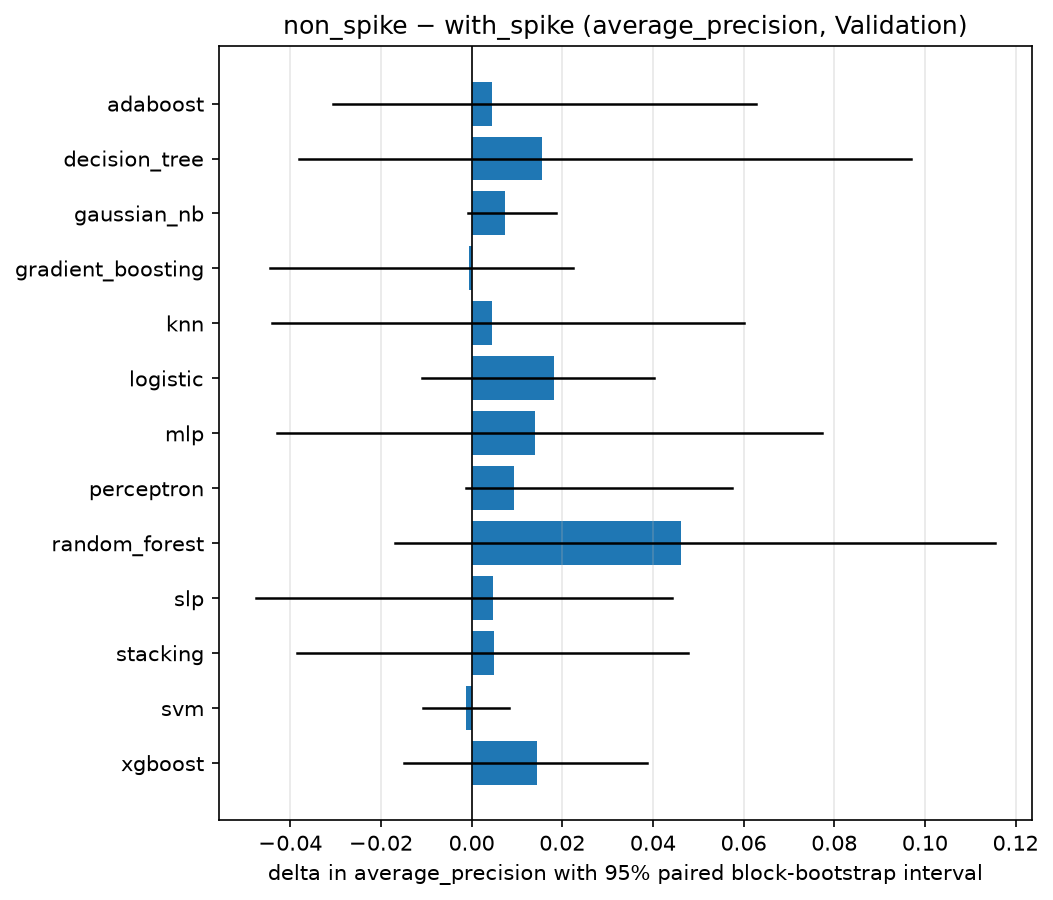

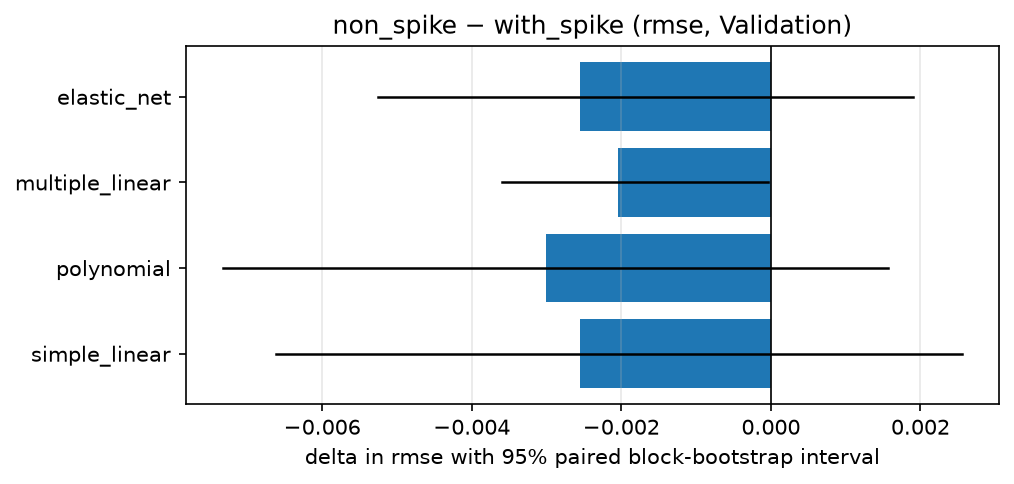

verdict,inconclusive,no interval,non_spike better
task,,,
classification,13,0,0
clustering,0,2,0
regression,3,0,1


In [6]:
show_markdown(REPORT_ROOT / "comparison_a_vs_b.md")
show_image(FIGURE_ROOT / "comparison_delta_classification.png", width=760)
show_image(FIGURE_ROOT / "comparison_delta_regression.png", width=760)
comparison = table(REPORT_ROOT / "comparison_a_vs_b.csv")
display(comparison.groupby(["task", "verdict"]).size().unstack(fill_value=0))

### อ่านผล with_spike เทียบ non_spike

- **ทิศทาง:** โมเดลส่วนใหญ่ได้คะแนนดีขึ้นเล็กน้อยเมื่อตัด spike ออก ทั้ง classification (AP สูงขึ้น) และ regression (RMSE ต่ำลง)
- **นัยสำคัญ:** เกือบทุกแถวได้คำตัดสิน `inconclusive` เพราะช่วง 95% คร่อมศูนย์ เมื่อเทียบ 17 โมเดลพร้อมกัน เราคาดว่าจะมีราว 1 โมเดลที่ช่วงไม่คร่อมศูนย์ด้วยความบังเอิญอยู่แล้ว
- **AdaBoost:** เราคาดไว้ว่า exponential loss จะไวต่อ spike เป็นพิเศษ แต่ `adaboost` เปลี่ยนน้อยและช่วงคร่อมศูนย์ ข้อมูลชุดนี้จึง **ไม่สนับสนุน** สมมติฐานนั้น
- **Clustering** ไม่มีช่วงความเชื่อมั่น จึงรายงานเฉพาะผลต่างของ silhouette

**ข้อสรุปที่ซื่อตรง:** จาก Validation ชุดนี้ เรายังสรุปไม่ได้ว่าการตัด spike ช่วยหรือทำร้ายโมเดล หลักฐานชี้ไปทาง "ช่วยเล็กน้อย" แต่ยังแยกจากความบังเอิญไม่ได้ และ Validation ไม่มีวัน spike เลย จึงทดสอบไม่ได้ว่าโมเดลแต่ละแบบรับมือ spike ได้ดีแค่ไหน คำถามนั้นต้องดูจาก Test ในหัวข้อ 8

## 5. Robustness ข้ามช่วงเวลา

อันดับบน Validation มาจากสภาพตลาดแบบเดียว เราเทียบกับอันดับจาก walk-forward ภายใน Train (อธิบายใน notebook 04 หัวข้อ 14) ซึ่งครอบคลุมหลายปีและมีวันผันผวนสูงมากกว่าหลายเท่า

**Spearman ρ** วัดว่าอันดับสองชุดตรงกันแค่ไหน: 1 = เหมือนกันทุกลำดับ, 0 = ไม่เกี่ยวกัน, ติดลบ = กลับด้าน

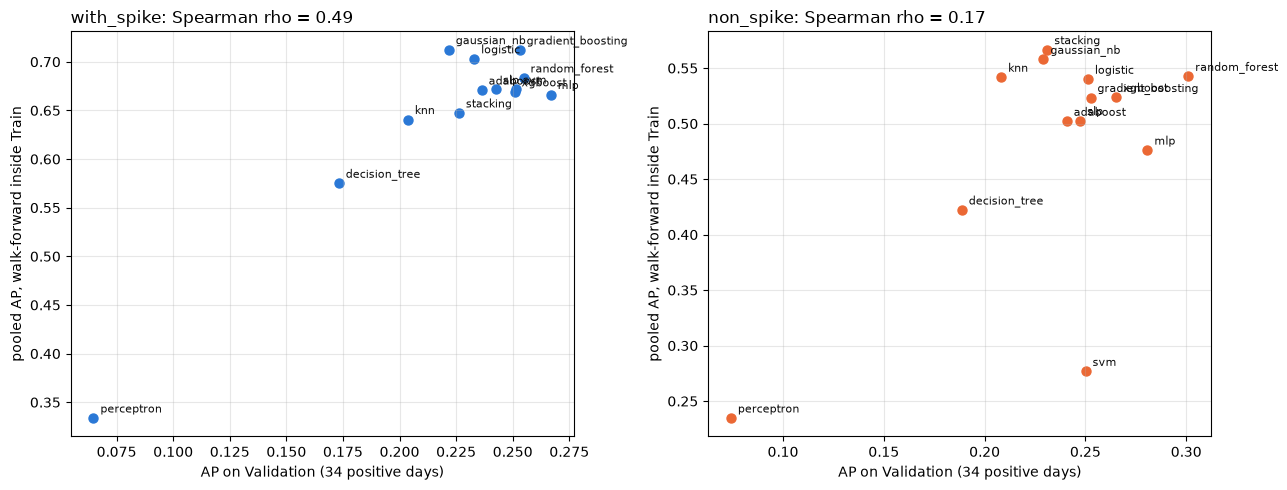

,variant,models,spearman rho,models scored on fewer than 4 folds
0,with_spike,13,0.489,stacking
1,non_spike,13,0.170,stacking


In [7]:
figure, panels = plt.subplots(1, 2, figsize=(13, 5))
rank_rows = []
for axes, variant in zip(panels, VARIANTS):
    board = boards["classification"]
    validation_ap = board[(board["variant"] == variant) & (board["kind"] == "model")].set_index("model")["average_precision"]
    walk = table(REPORT_ROOT / variant / "walk_forward.csv")
    pooled = walk[walk["fold"].astype(str) == "pooled"].set_index("model")
    joined = pd.DataFrame({"validation": validation_ap, "walk_forward": pooled["average_precision"],
                           "folds_used": pooled["folds_used"]}).dropna()
    rho = spearman(joined["validation"], joined["walk_forward"])
    rank_rows.append({"variant": variant, "models": len(joined), "spearman rho": round(rho, 3),
                      "models scored on fewer than 4 folds": ", ".join(joined.index[joined["folds_used"] < 4]) or "none"})
    axes.scatter(joined["validation"], joined["walk_forward"], s=42, color=COLORS[variant])
    for name, row in joined.iterrows():
        axes.annotate(name, (row["validation"], row["walk_forward"]), xytext=(5, 4),
                      textcoords="offset points", fontsize=8, color="#0b0b0b")
    axes.set_title(f"{variant}: Spearman rho = {rho:.2f}", loc="left")
    axes.set_xlabel("AP on Validation (34 positive days)")
    axes.set_ylabel("pooled AP, walk-forward inside Train")
    axes.grid(alpha=0.3)
figure.tight_layout()
plt.show()
display(pd.DataFrame(rank_rows))

**อ่านรูป:** ถ้าอันดับเสถียร จุดจะเรียงจากซ้ายล่างไปขวาบน ยิ่ง ρ ต่ำ ยิ่งแปลว่าอันดับบน Validation ขึ้นกับช่วงเวลาที่บังเอิญได้มาวัด และยิ่งต้องระวังการอ้างว่าโมเดลใดดีที่สุด

ค่า ρ ที่ได้อยู่ในระดับต่ำถึงปานกลาง (ดูตาราง) อันดับบน Validation จึงสะท้อนอันดับในช่วงเวลาอื่นได้เพียงบางส่วน ข้อสังเกตที่คงที่ทั้งสองมุมคือ `perceptron` และ `decision_tree` อยู่ท้ายตาราง ส่วนกลุ่มบนสลับอันดับกันไปมา

คะแนน AP ของ walk-forward สูงกว่า Validation มาก (ราว 0.6 ถึง 0.7 เทียบกับ 0.2 ถึง 0.3) เพราะช่วงทดสอบใน Train มีวันผันผวนสูงถึงราวหนึ่งในสาม AP จึงเทียบข้ามชุดข้อมูลที่มี positive rate ต่างกันไม่ได้ ใช้เทียบได้เฉพาะอันดับ

## 6. ฟีเจอร์ที่โมเดลพึ่งพา

รูปถัดไปเฉลี่ย permutation importance ข้าม classifier ทั้ง 13 ตัว เพื่อดูว่าโดยรวมโมเดลพึ่ง feature ใดมากที่สุด และรูปแบบนี้เปลี่ยนไหมเมื่อตัด spike ออก เส้นสีดำคือส่วนเบี่ยงเบนมาตรฐานระหว่างโมเดล

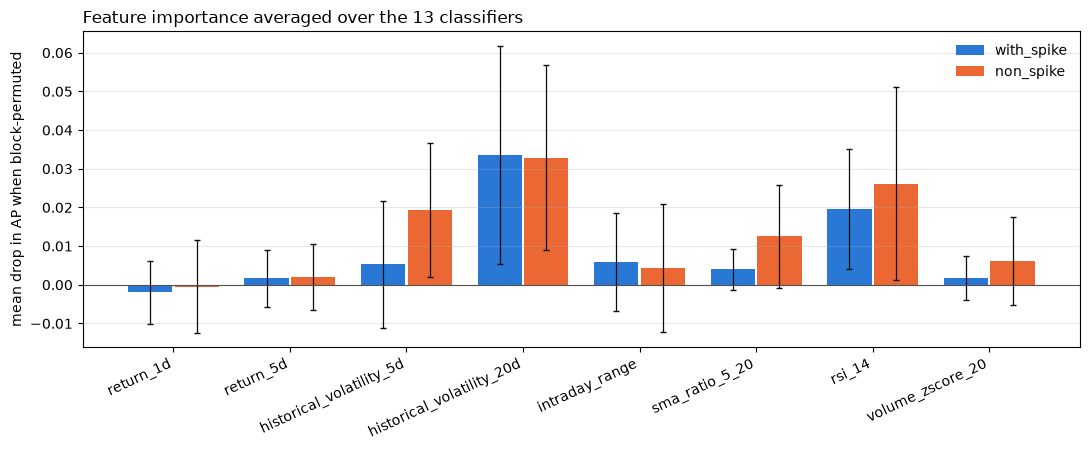

with_spike         non_spike        
                                mean     std      mean     std
feature                                                       
return_1d                    -0.0019  0.0081   -0.0005  0.0119
return_5d                     0.0017  0.0074    0.0020  0.0086
historical_volatility_5d      0.0053  0.0165    0.0193  0.0174
historical_volatility_20d     0.0336  0.0282    0.0329  0.0238
intraday_range                0.0060  0.0127    0.0044  0.0165
sma_ratio_5_20                0.0040  0.0054    0.0125  0.0133
rsi_14                        0.0197  0.0155    0.0261  0.0250
volume_zscore_20              0.0017  0.0057    0.0062  0.0113

In [8]:
average = {}
for variant in VARIANTS:
    importance = table(REPORT_ROOT / variant / "feature_importance.csv").query("task == 'classification'")
    average[variant] = importance.groupby("feature")["importance_mean"].agg(["mean", "std"]).reindex(list(FEATURE_COLUMNS))

figure, axes = plt.subplots(figsize=(11, 4.6))
positions = np.arange(len(FEATURE_COLUMNS))
for offset, variant in zip((-0.2, 0.2), VARIANTS):
    axes.bar(positions + offset, average[variant]["mean"], width=0.38, color=COLORS[variant], label=variant,
             yerr=average[variant]["std"], error_kw={"ecolor": "#0b0b0b", "elinewidth": 0.9, "capsize": 2})
axes.axhline(0, color="#52514e", linewidth=0.8)
axes.set_xticks(positions, FEATURE_COLUMNS, rotation=25, ha="right")
axes.set_ylabel("mean drop in AP when block-permuted")
axes.set_title("Feature importance averaged over the 13 classifiers", loc="left")
axes.grid(axis="y", alpha=0.3)
axes.legend(frameon=False)
figure.tight_layout()
plt.show()
display(pd.concat({variant: frame.round(4) for variant, frame in average.items()}, axis=1))

**อ่านรูป:** `historical_volatility_20d` เป็น feature ที่โมเดลพึ่งมากที่สุดทั้งสอง variant ตามด้วย `rsi_14` สอดคล้องกับปรากฏการณ์ volatility clustering ที่เห็นใน notebook 02: ช่วงผันผวนมักตามด้วยช่วงผันผวน ส่วน `return_1d` และ `volume_zscore_20` แทบไม่มีผล

สังเกตว่าเส้น std ยาวพอ ๆ กับความสูงของแท่งเกือบทุกแท่ง แปลว่าโมเดลแต่ละตัวพึ่ง feature ต่างกันมาก และอันดับที่ต่ำกว่าสองตัวแรกยังไม่น่าเชื่อถือ

ข้อจำกัดเดิมยังใช้อยู่: feature ที่สัมพันธ์กันแบ่งความสำคัญกัน และค่าตั้งอยู่บนวัน positive 34 วัน

## 7. พลาดตรงไหน (error analysis)

เราดูคำทำนายของ headline classifier ตามเวลา เพื่อหาว่าวันผันผวนสูงที่พลาดกระจุกอยู่ช่วงไหน

- **TP** = จับได้, **FN** = พลาด, **FP** = เตือนผิด

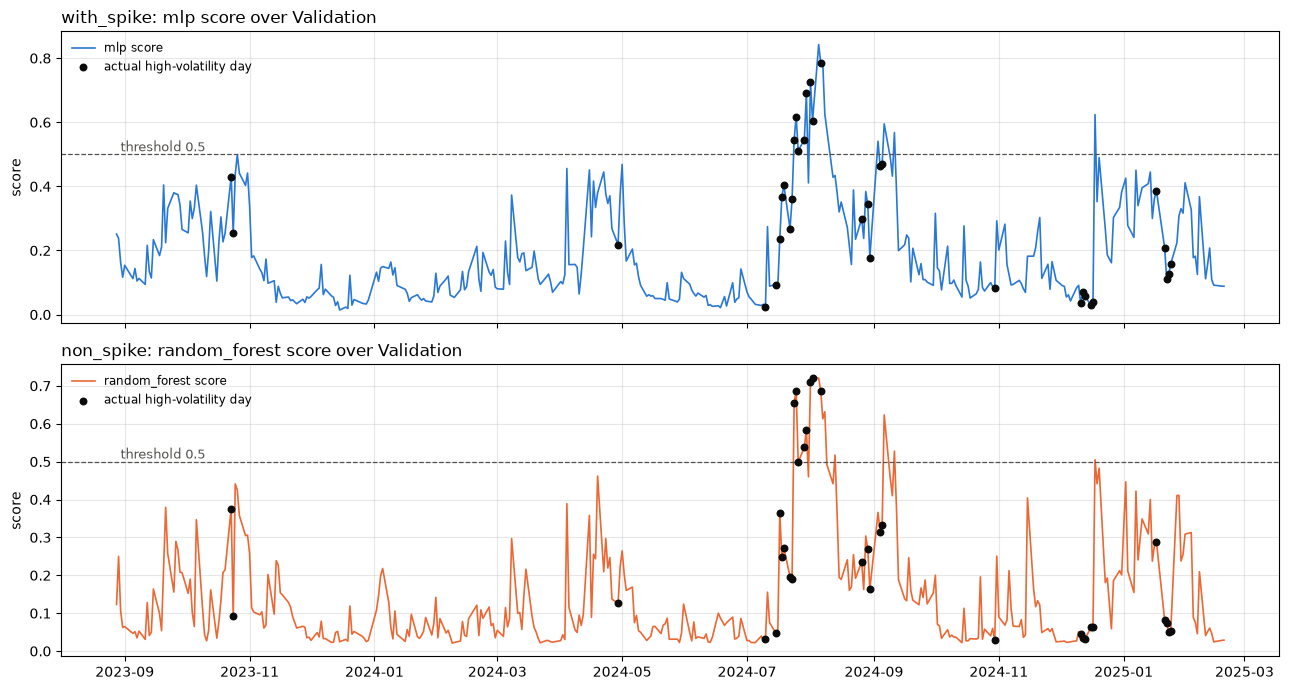

with_spike (mlp)           non_spike (random_forest)          
           positive days TP  FN FP             positive days TP  FN FP
quarter                                                               
2023Q3                 0  0   0  0                         0  0   0  0
2023Q4                 2  0   2  0                         2  0   2  0
2024Q1                 0  0   0  0                         0  0   0  0
2024Q2                 1  0   1  0                         1  0   1  0
2024Q3                20  8  12  7                        20  7  13  6
2024Q4                 6  0   6  1                         6  0   6  1
2025Q1                 5  0   5  0                         5  0   5  0

In [9]:
figure, panels = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
quarterly = {}
for axes, variant in zip(panels, VARIANTS):
    name = headline[f"{variant}/classification"]
    run = read_run(OUTPUT_ROOT, variant, name)
    frame = pd.DataFrame({"date": pd.to_datetime(run.dates), "y": run.target.astype(int),
                          "score": run.score, "label": run.prediction.astype(int)})
    frame["quarter"] = frame["date"].dt.to_period("Q").astype(str)
    frame["TP"] = (frame["y"] == 1) & (frame["label"] == 1)
    frame["FN"] = (frame["y"] == 1) & (frame["label"] == 0)
    frame["FP"] = (frame["y"] == 0) & (frame["label"] == 1)
    quarterly[f"{variant} ({name})"] = frame.groupby("quarter")[["y", "TP", "FN", "FP"]].sum().rename(
        columns={"y": "positive days"})
    axes.plot(frame["date"], frame["score"], color=COLORS[variant], linewidth=1.2, label=f"{name} score")
    positive = frame[frame["y"] == 1]
    axes.scatter(positive["date"], positive["score"], s=22, color="#0b0b0b", zorder=3,
                 label="actual high-volatility day")
    if run.metrics["score_kind"] == "probability":
        axes.axhline(0.5, color="#52514e", linestyle="--", linewidth=0.9)
        axes.text(frame["date"].iloc[0], 0.5, " threshold 0.5", va="bottom", fontsize=9, color="#52514e")
    axes.set_title(f"{variant}: {name} score over Validation", loc="left")
    axes.set_ylabel("score")
    axes.grid(alpha=0.3)
    axes.legend(frameon=False, loc="upper left", fontsize="small")
figure.tight_layout()
plt.show()
display(pd.concat(quarterly, axis=1))

**อ่านรูป:** จุดสีดำคือวันผันผวนสูงจริง ถ้าจุดอยู่ใต้เส้น threshold แปลว่าโมเดลพลาดวันนั้น

วันผันผวนสูงของ Validation กระจุกในไตรมาส 3 ปี 2024 (20 จาก 34 วัน ช่วงตลาดปรับฐานแรงต้นเดือนสิงหาคม) และ headline จับได้ **เฉพาะในไตรมาสนั้น** ส่วนวันผันผวนสูงอีก 14 วันที่กระจายอยู่ในไตรมาสอื่นพลาดทั้งหมด

คะแนนของโมเดลขึ้นตาม **หลัง** ความผันผวนเริ่มแล้ว เพราะ feature ทั้งหมดมองย้อนหลัง โมเดลจึงจับช่วงกลางและท้ายของเหตุการณ์ใหญ่ได้ แต่พลาดวันแรก ๆ และพลาดเหตุการณ์สั้น ๆ ซึ่งเป็นกรณีที่มีค่าที่สุดสำหรับการเตือนล่วงหน้า

## 8. ผลบน Test (อ่านครั้งเดียว)

**กติกาที่ใช้**

1. โมเดลเทรนจาก Train เท่านั้น และเลือกการตั้งค่าบน Validation
2. **ไม่ refit** โมเดลบน Train+Validation ก่อนวัด Test
3. ก่อนเปิด Test คำสั่ง `finalize --dry-run` บันทึก hash ของทั้ง 38 run และชื่อ headline ลง `selection_lock.json` แล้ว commit
4. คำสั่ง `finalize --allow-test` อ่าน Test **ครั้งเดียว** แล้วเขียนใบรับรอง `finalize_receipt.json` การรันซ้ำจะถูกปฏิเสธ

ตัวเลขในหัวข้อนี้จึงเป็นค่าประมาณเพียงชุดเดียวของโปรเจกต์ที่ไม่ถูกปนเปื้อนด้วยการเลือกโมเดล

Test (ก.พ. 2025 ถึง ส.ค. 2026) รวมช่วงตลาดผันผวนแรงเดือนเมษายน 2025 ซึ่งรุนแรงกว่าทุกอย่างใน Validation ผลจึงอาจต่างจาก Validation มาก

In [10]:
FINALIZED = RECEIPT_PATH.is_file()
if not FINALIZED:
    display(Markdown("**ยังไม่ได้ finalize** จึงยังไม่มีผลบน Test ให้แสดง "
                     "(ต้องรัน `python -m src.ml.run finalize --dry-run` แล้วตามด้วย `--allow-test` หนึ่งครั้ง)"))
else:
    receipt = json.loads(RECEIPT_PATH.read_text(encoding="utf-8"))
    display(pd.Series({key: receipt[key] for key in ("finalized_at_utc", "git_revision", "git_dirty", "holdout_rows",
                                                     "segment_rows", "run_count", "replicates", "rerun_reason",
                                                     "headline")}, name="finalize receipt").to_frame())
    for variant in VARIANTS:
        for task in ("classification", "regression"):
            show_markdown(FINAL_ROOT / variant / f"leaderboard_{task}.md")

,finalize receipt
finalized_at_utc,2026-10-11T14:02:01+00:00
git_revision,cb12d2251e41919f4883cc106ab23479f6b126d7
git_dirty,False
holdout_rows,373
segment_rows,"{'non_spike': 319, 'spike_affected': 54}"
run_count,38
replicates,2000
rerun_reason,None
headline,"{'non_spike/classification': 'random_forest', 'non_spike/regression': 'elast..."


### Test leaderboard — classification — with_spike

| model | kind | headline | validation_average_precision | average_precision_ci | roc_auc_ci | f1_ci | recall_ci | tied_with_leader | beats_best_baseline |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| mlp | model | yes | 0.2668 | 0.5991 [0.2605, 0.7603] | 0.7930 [0.6103, 0.9031] | 0.5714 [0.2104, 0.6929] | 0.4932 [0.1429, 0.6505] | yes | yes |
| random_forest | model | no | 0.2548 | 0.5775 [0.2366, 0.7393] | 0.7866 [0.5922, 0.8920] | 0.5000 [0.1764, 0.6047] | 0.4247 [0.1333, 0.5424] | yes | yes |
| svm | model | no | 0.2514 | 0.5716 [0.2402, 0.7438] | 0.7835 [0.5935, 0.8955] | 0.4874 [0.1176, 0.6102] | 0.3973 [0.0789, 0.5536] | yes | yes |
| gaussian_nb | model | no | 0.2218 | 0.5538 [0.2390, 0.7289] | 0.7703 [0.5749, 0.8838] | 0.5806 [0.3055, 0.6892] | 0.6164 [0.3158, 0.7444] | yes | yes |
| slp | model | no | 0.2427 | 0.5536 [0.2473, 0.7470] | 0.7798 [0.5865, 0.8954] | 0.5041 [0.1665, 0.6480] | 0.4247 [0.1052, 0.6186] | yes | yes |
| logistic | model | no | 0.2330 | 0.5518 [0.2482, 0.7452] | 0.7822 [0.5936, 0.8978] | 0.5203 [0.2083, 0.6564] | 0.4384 [0.1351, 0.6211] | yes | yes |
| knn | model | no | 0.2037 | 0.5472 [0.2187, 0.7309] | 0.7847 [0.6241, 0.8634] | 0.5512 [0.1886, 0.6804] | 0.4795 [0.1350, 0.6579] | yes | yes |
| baseline_persistence | baseline | no | n/a | 0.5365 [0.1589, 0.7246] | 0.7255 [0.5280, 0.8308] | 0.4933 [0.1599, 0.6335] | 0.5068 [0.1633, 0.6552] | yes | n/a |
| gradient_boosting | model | no | 0.2531 | 0.5332 [0.2223, 0.7096] | 0.7665 [0.5798, 0.8803] | 0.4390 [0.1591, 0.6000] | 0.3699 [0.1190, 0.5539] | yes | no |
| xgboost | model | no | 0.2508 | 0.5305 [0.2021, 0.7067] | 0.7716 [0.5844, 0.8839] | 0.4553 [0.1795, 0.6078] | 0.3836 [0.1333, 0.5582] | yes | no |
| stacking | model | no | 0.2262 | 0.5131 [0.2395, 0.7154] | 0.7902 [0.6082, 0.8877] | 0.5714 [0.2898, 0.6842] | 0.5753 [0.2439, 0.7385] | yes | no |
| adaboost | model | no | 0.2363 | 0.4858 [0.2145, 0.6807] | 0.7614 [0.5710, 0.8785] | 0.4853 [0.2268, 0.6555] | 0.4521 [0.1852, 0.6775] | no | no |
| decision_tree | model | no | 0.1732 | 0.3792 [0.1524, 0.5643] | 0.7450 [0.6021, 0.8449] | 0.4800 [0.2000, 0.6667] | 0.4932 [0.1621, 0.7527] | no | no |
| baseline_majority | baseline | no | n/a | 0.1957 [0.0885, 0.3003] | 0.5000 [0.5000, 0.5000] | 0.0000 [0.0000, 0.0000] | 0.0000 [0.0000, 0.0000] | no | n/a |
| perceptron | model | no | 0.0648 | 0.1374 [0.0657, 0.2463] | 0.2749 [0.1567, 0.4688] | 0.0577 [0.0000, 0.1840] | 0.0411 [0.0000, 0.1690] | no | no |

> ประเมินบน Test ครั้งเดียวด้วยโมเดลที่เทรนจาก Train และเลือกบน Validation (ไม่ refit) โมเดลเด่นของแต่ละ task ถูกระบุไว้ใน selection_lock.json ก่อนเปิด Test แถวอื่นในตารางเป็นข้อมูลประกอบ ห้ามเลือกโมเดลจากตารางนี้


### Test leaderboard — regression — with_spike

| model | kind | headline | validation_rmse | rmse_ci | r2_ci | tied_with_leader | beats_best_baseline |
| --- | --- | --- | --- | --- | --- | --- | --- |
| multiple_linear | model | no | 0.0689 | 0.1158 [0.0711, 0.1680] | 0.2959 [-0.1971, 0.3897] | yes | yes |
| elastic_net | model | yes | 0.0668 | 0.1174 [0.0709, 0.1746] | 0.2758 [-0.0402, 0.3258] | yes | yes |
| simple_linear | model | no | 0.0690 | 0.1356 [0.0754, 0.1985] | 0.0347 [-0.7702, 0.2310] | no | yes |
| baseline_train_mean | baseline | no | n/a | 0.1380 [0.0806, 0.2060] | -0.0006 [-0.2998, -0.0000] | yes | n/a |
| polynomial | model | no | 0.0691 | 0.1401 [0.0754, 0.2037] | -0.0314 [-1.1539, 0.2401] | no | no |
| baseline_persistence | baseline | no | n/a | 0.1502 [0.0919, 0.2222] | -0.1855 [-1.2071, 0.1280] | no | n/a |

> ประเมินบน Test ครั้งเดียวด้วยโมเดลที่เทรนจาก Train และเลือกบน Validation (ไม่ refit) โมเดลเด่นของแต่ละ task ถูกระบุไว้ใน selection_lock.json ก่อนเปิด Test แถวอื่นในตารางเป็นข้อมูลประกอบ ห้ามเลือกโมเดลจากตารางนี้


### Test leaderboard — classification — non_spike

| model | kind | headline | validation_average_precision | average_precision_ci | roc_auc_ci | f1_ci | recall_ci | tied_with_leader | beats_best_baseline |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| gaussian_nb | model | no | 0.2292 | 0.5884 [0.2441, 0.7462] | 0.7779 [0.5735, 0.8913] | 0.5824 [0.3299, 0.6817] | 0.7260 [0.4210, 0.8530] | yes | yes |
| xgboost | model | no | 0.2652 | 0.5823 [0.2509, 0.7436] | 0.7887 [0.6017, 0.8948] | 0.5469 [0.2034, 0.7000] | 0.4795 [0.1463, 0.6812] | yes | yes |
| svm | model | no | 0.2501 | 0.5805 [0.2446, 0.7504] | 0.7853 [0.5967, 0.8990] | 0.4587 [0.0974, 0.5922] | 0.3425 [0.0588, 0.5048] | yes | yes |
| gradient_boosting | model | no | 0.2525 | 0.5653 [0.2460, 0.7310] | 0.7861 [0.6087, 0.8920] | 0.3762 [0.1290, 0.5264] | 0.2603 [0.0789, 0.4000] | yes | yes |
| mlp | model | no | 0.2808 | 0.5639 [0.2507, 0.7235] | 0.7894 [0.5922, 0.8906] | 0.5039 [0.2127, 0.6449] | 0.4384 [0.1578, 0.6165] | yes | yes |
| logistic | model | no | 0.2513 | 0.5510 [0.2472, 0.7391] | 0.7782 [0.5841, 0.8940] | 0.5041 [0.1785, 0.6269] | 0.4247 [0.1111, 0.5943] | yes | yes |
| stacking | model | no | 0.2311 | 0.5499 [0.2440, 0.7150] | 0.7890 [0.6135, 0.8828] | 0.4853 [0.2432, 0.6016] | 0.4521 [0.2057, 0.5843] | yes | yes |
| adaboost | model | no | 0.2407 | 0.5443 [0.2261, 0.7297] | 0.7735 [0.5788, 0.8899] | 0.5000 [0.2051, 0.6348] | 0.4110 [0.1470, 0.5758] | yes | yes |
| knn | model | no | 0.2082 | 0.5389 [0.2514, 0.7067] | 0.8008 [0.6595, 0.8698] | 0.4237 [0.0894, 0.5658] | 0.3425 [0.0606, 0.4943] | yes | yes |
| baseline_persistence | baseline | no | n/a | 0.5365 [0.1589, 0.7246] | 0.7255 [0.5280, 0.8308] | 0.4933 [0.1599, 0.6335] | 0.5068 [0.1633, 0.6552] | yes | n/a |
| random_forest | model | yes | 0.3010 | 0.5240 [0.2161, 0.6796] | 0.7814 [0.5879, 0.8807] | 0.4715 [0.1667, 0.5556] | 0.3973 [0.1249, 0.4923] | yes | no |
| slp | model | no | 0.2474 | 0.4963 [0.2080, 0.6769] | 0.7420 [0.5497, 0.8583] | 0.5000 [0.2564, 0.6053] | 0.4795 [0.2143, 0.6164] | no | no |
| decision_tree | model | no | 0.1887 | 0.3844 [0.1761, 0.5137] | 0.6916 [0.5598, 0.7827] | 0.4310 [0.2142, 0.5246] | 0.3425 [0.1579, 0.4272] | no | no |
| baseline_majority | baseline | no | n/a | 0.1957 [0.0885, 0.3003] | 0.5000 [0.5000, 0.5000] | 0.0000 [0.0000, 0.0000] | 0.0000 [0.0000, 0.0000] | no | n/a |
| perceptron | model | no | 0.0742 | 0.1328 [0.0624, 0.2276] | 0.2626 [0.1410, 0.4434] | 0.0813 [0.0000, 0.2460] | 0.0685 [0.0000, 0.2817] | no | no |

> ประเมินบน Test ครั้งเดียวด้วยโมเดลที่เทรนจาก Train และเลือกบน Validation (ไม่ refit) โมเดลเด่นของแต่ละ task ถูกระบุไว้ใน selection_lock.json ก่อนเปิด Test แถวอื่นในตารางเป็นข้อมูลประกอบ ห้ามเลือกโมเดลจากตารางนี้


### Test leaderboard — regression — non_spike

| model | kind | headline | validation_rmse | rmse_ci | r2_ci | tied_with_leader | beats_best_baseline |
| --- | --- | --- | --- | --- | --- | --- | --- |
| polynomial | model | no | 0.0661 | 0.1142 [0.0720, 0.1641] | 0.3155 [-0.0360, 0.4224] | yes | yes |
| multiple_linear | model | no | 0.0668 | 0.1180 [0.0705, 0.1732] | 0.2684 [-0.1829, 0.3623] | yes | yes |
| elastic_net | model | yes | 0.0643 | 0.1230 [0.0688, 0.1859] | 0.2059 [0.0554, 0.2619] | yes | yes |
| simple_linear | model | no | 0.0665 | 0.1372 [0.0733, 0.2087] | 0.0114 [-0.1001, 0.0488] | yes | yes |
| baseline_train_mean | baseline | no | n/a | 0.1400 [0.0745, 0.2132] | -0.0298 [-0.1430, -0.0001] | yes | n/a |
| baseline_persistence | baseline | no | n/a | 0.1502 [0.0919, 0.2222] | -0.1855 [-1.2071, 0.1280] | no | n/a |

> ประเมินบน Test ครั้งเดียวด้วยโมเดลที่เทรนจาก Train และเลือกบน Validation (ไม่ refit) โมเดลเด่นของแต่ละ task ถูกระบุไว้ใน selection_lock.json ก่อนเปิด Test แถวอื่นในตารางเป็นข้อมูลประกอบ ห้ามเลือกโมเดลจากตารางนี้


รูปถัดไปเทียบคะแนนของโมเดลเดียวกันบน Validation (แกนนอน) กับบน Test (แกนตั้ง) จุดบนเส้นทแยงคือคะแนนเท่ากันทั้งสองชุด

ข้อควรระวัง: AP ขึ้นกับสัดส่วนวัน positive ซึ่งต่างกันระหว่าง Validation (9.2%) กับ Test (19.6%) AP บน Test จึงสูงกว่าได้โดยที่โมเดลไม่ได้เก่งขึ้น ต้องเทียบกับ baseline ของชุดเดียวกันเสมอ

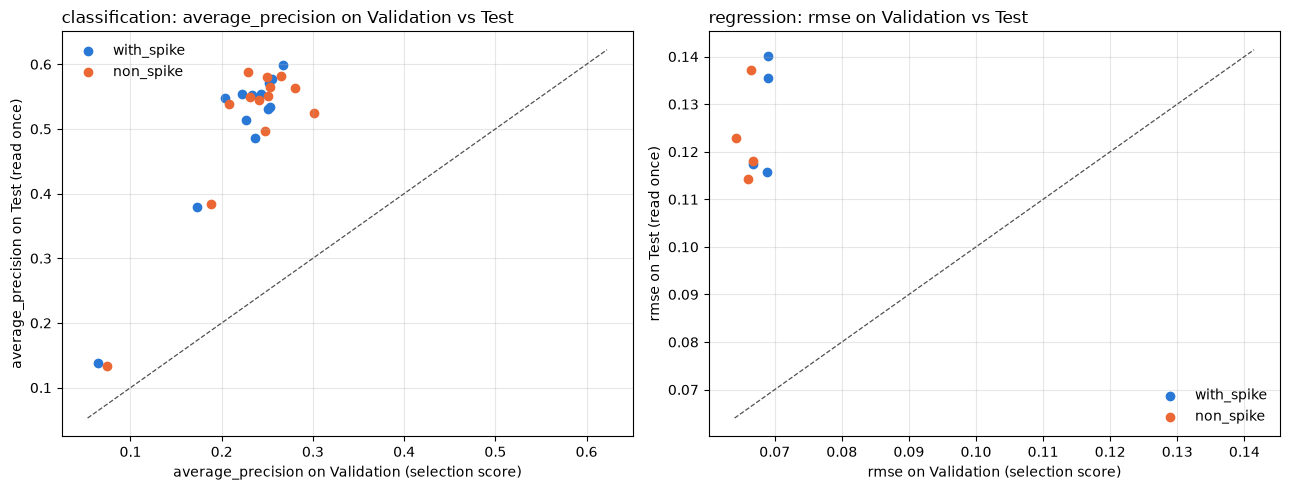

,task,variant,headline,validation,test,test low,test high,best baseline on test,baseline test,headline beats baseline,metric
0,classification,with_spike,mlp,0.2668,0.5991,0.2605,0.7603,baseline_persistence,0.5365,True,average_precision
1,classification,non_spike,random_forest,0.3010,0.5240,0.2161,0.6796,baseline_persistence,0.5365,False,average_precision
2,regression,with_spike,elastic_net,0.0668,0.1174,0.0709,0.1746,baseline_train_mean,0.1380,True,rmse
3,regression,non_spike,elastic_net,0.0643,0.1230,0.0688,0.1859,baseline_train_mean,0.1400,True,rmse


In [11]:
if FINALIZED:
    figure, panels = plt.subplots(1, 2, figsize=(13, 5))
    headline_rows = []
    for axes, task in zip(panels, ("classification", "regression")):
        field, higher = PRIMARY[task]
        for variant in VARIANTS:
            final = table(FINAL_ROOT / variant / f"leaderboard_{task}.csv")
            models = final[final["kind"] == "model"]
            axes.scatter(models[f"validation_{field}"], models[field], s=36, color=COLORS[variant], label=variant)
            chosen = final[final["headline"] == True].iloc[0]
            best_rule = final[final["kind"] == "baseline"].sort_values(field, ascending=not higher).iloc[0]
            headline_rows.append({"task": task, "variant": variant, "headline": chosen["model"],
                                  f"validation": chosen[f"validation_{field}"], "test": chosen[field],
                                  "test low": chosen[f"{field}_low"], "test high": chosen[f"{field}_high"],
                                  "best baseline on test": best_rule["model"], "baseline test": best_rule[field],
                                  "headline beats baseline": bool(chosen["beats_best_baseline"]),
                                  "metric": field})
        low = min(axes.get_xlim()[0], axes.get_ylim()[0])
        high = max(axes.get_xlim()[1], axes.get_ylim()[1])
        axes.plot([low, high], [low, high], color="#52514e", linestyle="--", linewidth=0.9)
        axes.set_title(f"{task}: {field} on Validation vs Test", loc="left")
        axes.set_xlabel(f"{field} on Validation (selection score)")
        axes.set_ylabel(f"{field} on Test (read once)")
        axes.grid(alpha=0.3)
        axes.legend(frameon=False)
    figure.tight_layout()
    (FIGURE_ROOT / "final").mkdir(parents=True, exist_ok=True)
    figure.savefig(FIGURE_ROOT / "final" / "validation_vs_test.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(pd.DataFrame(headline_rows).round(4))

ตารางถัดไปแยกผลของ headline ตามชนิดของวันใน Test

- `spike_affected`: 54 แถวที่อยู่ในหน้าต่างรอบวัน spike ของ Test
- `non_spike`: 319 แถวที่เหลือ (ช่วงตลาดปกติ)

นี่คือที่เดียวในโปรเจกต์ที่ตอบได้ตรง ๆ ว่าโมเดลที่เทรนแบบมี/ไม่มี spike รับมือกับช่วง spike จริงต่างกันไหม แต่ช่วง spike มีเพียง 54 แถว จึงไม่มีช่วงความเชื่อมั่น และต้องอ่านเป็นข้อสังเกต ไม่ใช่ข้อพิสูจน์

In [12]:
if FINALIZED:
    segmented = table(FINAL_ROOT / "segmented_metrics.csv")
    shown = {"classification": sorted({headline[f"{variant}/classification"] for variant in VARIANTS}
                                      | {"adaboost", "logistic"}),
             "regression": ["elastic_net", "multiple_linear"]}
    for task, names in shown.items():
        field, _ = PRIMARY[task]
        keep = [column for column in ("rows", "positives", field, "roc_auc", "recall", "f1", "mae", "r2")
                if column in segmented.columns]
        chosen = segmented[(segmented["task"] == task) & segmented["model"].isin(names)]
        chosen = chosen.sort_values(["model", "variant", "segment"]).set_index(["model", "variant", "segment"])
        display(chosen[keep].dropna(axis=1, how="all").round(4))

rows  positives  average_precision  roc_auc  recall      f1
model         variant    segment                                                                    
adaboost      non_spike  non_spike        319       35.0             0.3372   0.7370  0.3714  0.4333
                         spike_affected    54       38.0             0.8281   0.6102  0.4474  0.5667
              with_spike non_spike        319       35.0             0.3212   0.7251  0.3429  0.3750
                         spike_affected    54       38.0             0.6804   0.3413  0.5526  0.5833
logistic      non_spike  non_spike        319       35.0             0.3639   0.7444  0.2000  0.2917
                         spike_affected    54       38.0             0.7200   0.3668  0.6316  0.6400
              with_spike non_spike        319       35.0             0.3882   0.7545  0.2286  0.3333
                         spike_affected    54       38.0             0.7168   0.3734  0.6316  0.6400
mlp           non_spike  non_spike        319       35.0             0.4048   0.7454  0.2857  0.3704
                         spike_affected    54       38.0             0.7310   0.4227  0.5789  0.6027
              with_spike non_spike        319       35.0             0.4451   0.7709  0.3429  0.4286
                         spike_affected    54       38.0             0.7837   0.5296  0.6316  0.6857
random_forest non_spike  non_spike        319       35.0             0.3898   0.7344  0.3714  0.4194
                         spike_affected    54       38.0             0.7664   0.5510  0.4211  0.5246
              with_spike non_spike        319       35.0             0.3782   0.7455  0.3429  0.4000
                         spike_affected    54       38.0             0.8011   0.5757  0.5000  0.5938

rows    rmse     mae      r2
model           variant    segment                                     
elastic_net     non_spike  non_spike        319  0.0692  0.0550  0.1752
                           spike_affected    54  0.2759  0.1838 -0.3351
                with_spike non_spike        319  0.0707  0.0564  0.1395
                           spike_affected    54  0.2564  0.1722 -0.1526
multiple_linear non_spike  non_spike        319  0.0683  0.0525  0.1972
                           spike_affected    54  0.2620  0.1880 -0.2042
                with_spike non_spike        319  0.0694  0.0536  0.1714
                           spike_affected    54  0.2533  0.1819 -0.1253

รูปถัดไปแสดง ROC-AUC ของ classifier ทุกตัวแยกตามช่วง เส้นประคือ 0.5 ซึ่งเท่ากับการเดาสุ่ม จุดสีน้ำเงินคือช่วงตลาดปกติ จุดสีส้มคือช่วงรอบวัน spike ถ้าโมเดลแยกวันผันผวนสูงได้ดีในทั้งสองช่วง จุดทั้งสองสีจะอยู่สูงกว่าเส้นประชัดเจน

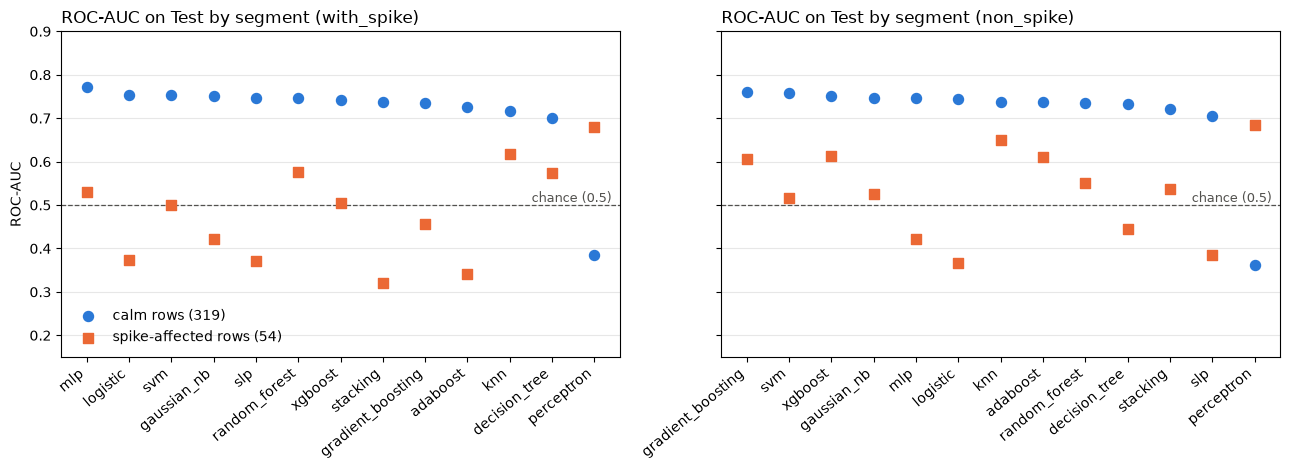

In [13]:
if FINALIZED:
    classifiers = segmented[segmented["task"] == "classification"]
    figure, panels = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
    styles = {"non_spike": ("#2a78d6", "o", "calm rows (319)"), "spike_affected": ("#eb6834", "s", "spike-affected rows (54)")}
    for axes, variant in zip(panels, VARIANTS):
        part = classifiers[classifiers["variant"] == variant]
        order = (part[part["segment"] == "non_spike"].sort_values("roc_auc", ascending=False)["model"].tolist())
        positions = np.arange(len(order))
        for segment, (color, marker, label) in styles.items():
            values = part[part["segment"] == segment].set_index("model")["roc_auc"].reindex(order)
            axes.scatter(positions, values, s=52, color=color, marker=marker, label=label, zorder=3)
        axes.axhline(0.5, color="#52514e", linestyle="--", linewidth=0.9)
        axes.text(len(order) - 0.5, 0.5, "chance (0.5) ", ha="right", va="bottom", fontsize=9, color="#52514e")
        axes.set_xticks(positions, order, rotation=40, ha="right")
        axes.set_title(f"ROC-AUC on Test by segment ({variant})", loc="left")
        axes.set_ylim(0.15, 0.9)
        axes.grid(axis="y", alpha=0.3)
    panels[0].set_ylabel("ROC-AUC")
    panels[0].legend(frameon=False, loc="lower left")
    figure.tight_layout()
    figure.savefig(FIGURE_ROOT / "final" / "test_roc_auc_by_segment.png", dpi=150, bbox_inches="tight")
    plt.show()

สองตารางถัดไปใช้คำทำนายบน Test ที่ `finalize` บันทึกไว้ (`test_predictions.csv`) ไม่ได้เปิดไฟล์ Test ซ้ำ

1. **headline เทียบโมเดลในห้องเรียนบน Test** ใช้วิธี paired block bootstrap เดียวกับหัวข้อ 3 ซึ่งกำหนดไว้ก่อนเปิด Test
2. **โมเดลเดียวกัน เทรนแบบมี spike เทียบแบบไม่มี spike บน Test** `delta = non_spike − with_spike`

ทั้งสองตารางเป็นการรายงานผล ไม่ได้ใช้เลือกหรือเปลี่ยนโมเดลใด

In [14]:
if FINALIZED:
    def holdout_entry(variant, name):
        frame = table(read_run(OUTPUT_ROOT, variant, name).directory / "test_predictions.csv")
        return {"model": name, "kind": "model", "target": frame["target"].to_numpy(dtype=float),
                "score": frame["raw_score"].to_numpy(dtype=float),
                "prediction": frame["final_prediction"].to_numpy(dtype=float)}

    holdout_indices = block_indices(int(receipt["holdout_rows"]))
    test_gains = []
    for task, reference in (("classification", "logistic"), ("regression", "multiple_linear")):
        field, higher = PRIMARY[task]
        for variant in VARIANTS:
            name = headline[f"{variant}/{task}"]
            base, best = score_entries(task, [holdout_entry(variant, reference), holdout_entry(variant, name)],
                                       holdout_indices)
            gap = difference(base["point"][field], base["replicates"][field],
                             best["point"][field], best["replicates"][field])
            test_gains.append({"task": task, "variant": variant, "metric": field, "classroom model": reference,
                               "classroom score": base["point"][field], "headline": name,
                               "headline score": best["point"][field], "delta": gap["point"],
                               "delta low": gap["low"], "delta high": gap["high"],
                               "improvement %": 100 * gap["point"] / base["point"][field] * (1 if higher else -1),
                               "interval excludes zero": gap["excludes_zero"]})
    display(pd.DataFrame(test_gains).round(4))

    across = []
    for task in ("classification", "regression"):
        field, higher = PRIMARY[task]
        names = table(FINAL_ROOT / "with_spike" / f"leaderboard_{task}.csv").query("kind == 'model'")["model"]
        for name in sorted(names):
            kept, removed = score_entries(task, [holdout_entry("with_spike", name), holdout_entry("non_spike", name)],
                                          holdout_indices)
            gap = difference(kept["point"][field], kept["replicates"][field],
                             removed["point"][field], removed["replicates"][field])
            better = gap["point"] > 0 if higher else gap["point"] < 0
            across.append({"task": task, "model": name, "metric": field, "with_spike": kept["point"][field],
                           "non_spike": removed["point"][field], "delta": gap["point"], "delta low": gap["low"],
                           "delta high": gap["high"],
                           "direction": "non_spike better" if better else "with_spike better",
                           "interval excludes zero": gap["excludes_zero"]})
    across = pd.DataFrame(across)
    display(across.round(4))
    display(across.groupby(["task", "direction", "interval excludes zero"]).size().rename("models").to_frame())

,task,variant,metric,classroom model,classroom score,headline,headline score,delta,delta low,delta high,improvement %,interval excludes zero
0,classification,with_spike,average_precision,logistic,0.5518,mlp,0.5991,0.0473,-0.0137,0.0766,8.5643,False
1,classification,non_spike,average_precision,logistic,0.5510,random_forest,0.5240,-0.0270,-0.1678,0.0793,-4.8974,False
2,regression,with_spike,rmse,multiple_linear,0.1158,elastic_net,0.1174,0.0016,-0.0092,0.0089,-1.4215,False
3,regression,non_spike,rmse,multiple_linear,0.1180,elastic_net,0.1230,0.0049,-0.0119,0.0158,-4.1832,False


,task,model,metric,with_spike,non_spike,delta,delta low,delta high,direction,interval excludes zero
0,classification,adaboost,average_precision,0.4858,0.5443,0.0585,-0.0324,0.1168,non_spike better,False
1,classification,decision_tree,average_precision,0.3792,0.3844,0.0052,-0.1502,0.1190,non_spike better,False
2,classification,gaussian_nb,average_precision,0.5538,0.5884,0.0346,-0.0064,0.0632,non_spike better,False
3,classification,gradient_boosting,average_precision,0.5332,0.5653,0.0322,-0.0254,0.0891,non_spike better,False
4,classification,knn,average_precision,0.5472,0.5389,-0.0083,-0.1005,0.0946,with_spike better,False
5,classification,logistic,average_precision,0.5518,0.5510,-0.0008,-0.0184,0.0156,with_spike better,False
6,classification,mlp,average_precision,0.5991,0.5639,-0.0352,-0.0792,0.0276,with_spike better,False
7,classification,perceptron,average_precision,0.1374,0.1328,-0.0046,-0.0313,-0.0001,with_spike better,True
8,classification,random_forest,average_precision,0.5775,0.5240,-0.0534,-0.1284,0.0106,with_spike better,False
9,classification,slp,average_precision,0.5536,0.4963,-0.0573,-0.1184,-0.0038,with_spike better,True


models
task           direction         interval excludes zero        
classification non_spike better  False                        6
                                 True                         1
               with_spike better False                        4
                                 True                         2
regression     non_spike better  False                        1
               with_spike better False                        3

### อ่านผล Test

**1. โมเดลมีความสามารถจริง แต่ส่วนใหญ่ไม่ได้เหนือกว่า baseline อย่างชัดเจน**

- classifier headline ของ `with_spike` คือ `mlp` ได้ AP 0.599 (ช่วง 95%: 0.261 ถึง 0.760) และ ROC-AUC 0.793 เทียบกับการเดาสุ่มที่ AP 0.196 และ `baseline_persistence` ที่ AP 0.537 โมเดลนี้ยังเป็นอันดับหนึ่งบน Test ด้วย
- classifier headline ของ `non_spike` คือ `random_forest` ได้ AP 0.524 **ต่ำกว่า** `baseline_persistence` และตกจากอันดับ 1 บน Validation ไปอยู่อันดับ 10 จาก 13 โมเดลบน Test นี่คือตัวอย่างตรง ๆ ของ selection bias: ผู้นำบน Validation ที่มีวัน positive เพียง 34 วัน ไม่จำเป็นต้องเป็นผู้นำบนข้อมูลใหม่
- regression headline `elastic_net` ได้ RMSE 0.117 (`with_spike`) และ 0.123 (`non_spike`) ดีกว่า baseline ที่ทายค่าเฉลี่ยของ Train (0.138 และ 0.140) และได้ R² ราว 0.2 ถึง 0.3

**2. โมเดลนอกห้องเรียนไม่ได้ดีกว่าโมเดลในห้องเรียนอย่างมีนัยสำคัญ**

ตาราง "headline เทียบโมเดลในห้องเรียนบน Test" ใช้วิธีเดียวกับหัวข้อ 3 ทุกประการ ช่วง 95% ของผลต่างคร่อมศูนย์ทั้ง 4 แถว `mlp` ดีกว่า `logistic` ราว 8.6% แต่ยังแยกจากความบังเอิญไม่ได้ ส่วน `elastic_net` ได้ RMSE แย่กว่า `multiple_linear` เล็กน้อยบน Test เราจึง **ไม่อ้าง** ว่าโมเดลที่ซับซ้อนกว่าดีกว่าโมเดลพื้นฐานอย่างชัดเจน

**3. ความสามารถของโมเดลอยู่ที่ช่วงตลาดปกติ ไม่ใช่ช่วง spike**

ตารางแยกช่วงบอกเรื่องที่ตัวเลขรวมซ่อนไว้

- **ช่วงปกติ** (319 แถว มีวันผันผวนสูง 35 วัน หรือ 11%): `mlp` ได้ AP 0.445 และ ROC-AUC 0.771 สูงกว่าการเดาสุ่ม (0.11) ชัดเจน regression ได้ RMSE ราว 0.07 ใกล้เคียงกับบน Validation
- **ช่วงรอบวัน spike** (54 แถว มีวันผันผวนสูง 38 วัน หรือ 70%): ROC-AUC ของ classifier ในตารางอยู่ระหว่าง 0.34 ถึง 0.61 คือใกล้หรือต่ำกว่าการเดาสุ่ม (0.5) แปลว่า **ภายในช่วงปั่นป่วน โมเดลแยกไม่ได้ว่าวันไหนจะผันผวนสูง** AP ที่ดูสูง (0.7 ถึง 0.8) มาจากการที่วันส่วนใหญ่ในช่วงนี้เป็น positive อยู่แล้ว ส่วน regression ได้ RMSE ราว 0.25 ถึง 0.28 และ R² ติดลบ

AP รวมบน Test ที่สูงกว่า Validation มาก (0.6 เทียบกับ 0.27) จึงไม่ได้แปลว่าโมเดลเก่งขึ้น ส่วนใหญ่มาจากสัดส่วนวัน positive ที่สูงขึ้น (19.6% เทียบกับ 9.2%) และจากการที่โมเดลรู้ว่า "ตอนนี้ตลาดกำลังปั่นป่วน" ซึ่ง `baseline_persistence` ก็รู้เช่นกัน

**4. ตัด spike ออกจาก Train: ยังสรุปไม่ได้ และทิศทางบน Test ไม่ตรงกับ Validation**

- บน Validation โมเดลส่วนใหญ่ดีขึ้นเล็กน้อยเมื่อตัด spike บน Test ผลแบ่งครึ่ง: classifier 6 ตัวแย่ลงและ 7 ตัวดีขึ้น ส่วน regression 3 จาก 4 ตัวแย่ลงเล็กน้อย
- จากตารางสุดท้ายของหัวข้อนี้ ช่วง 95% ของผลต่างคร่อมศูนย์ใน 14 จาก 17 โมเดล อีก 3 โมเดลที่ช่วงไม่คร่อมศูนย์ **ชี้ไปคนละทาง**: `slp` และ `perceptron` ดีกว่าเมื่อเก็บ spike ไว้ ส่วน `xgboost` ดีกว่าเมื่อตัด spike ออก เมื่อเทียบ 17 โมเดลพร้อมกัน การเจอช่วงที่ไม่คร่อมศูนย์ราว 1 โมเดลโดยบังเอิญเป็นเรื่องปกติ ผลนี้จึงไม่ใช่หลักฐานของผลที่เป็นระบบ
- ข้อสังเกตจากตารางแยกช่วง (ไม่มีช่วงความเชื่อมั่น): โมเดลเชิงเส้นที่เทรนแบบไม่มี spike ทำได้ดีกว่าเล็กน้อยในช่วงปกติ แต่แย่กว่าในช่วงรอบวัน spike ซึ่งสมเหตุสมผล เพราะโมเดลไม่เคยเห็นตัวอย่างแบบนั้นตอนเทรน
- `adaboost` เป็นโมเดลที่ดีขึ้นมากที่สุดเมื่อตัด spike (AP 0.486 เป็น 0.544) สอดคล้องกับสมมติฐานว่า exponential loss ไวต่อจุดสุดโต่ง แต่ช่วงของผลต่างยังคร่อมศูนย์ จึงเป็นเพียงข้อสังเกต

**ข้อสรุปของคำถามวิจัย:** ข้อมูลชุดนี้ **ไม่สนับสนุน** ว่าการตัดช่วง spike ออกจาก Train ทำให้โมเดลทำนายดีขึ้น และไม่สนับสนุนว่าทำให้แย่ลงเช่นกัน ผลต่างที่วัดได้เล็กกว่าความไม่แน่นอนของการวัด ทั้งบน Validation และ Test

## 9. เทียบกับ library (parity demo)

เหมือนเล่ม 03 และ 04: โมเดลของเราโหลดจากไฟล์ ส่วน scikit-learn ถูก fit ตรงนี้บนข้อมูลเดียวกัน แล้วเทียบคำทำนายบน Validation ทีละแถว เล่มนี้ใช้ `decision_tree` ซึ่งต้องตรงกันทุกแถวพอดี

In [15]:
PARITY_MODELS = ['decision_tree']


def parity_demo(name, variant="with_spike"):
    """Scratch model reloaded from disk vs the library reference fitted on the same inputs."""
    data = load(variant)
    run = read_run(OUTPUT_ROOT, variant, name)
    scratch, transform = load_model(run.directory)
    train_X, validation_X = transform(data.train.X), transform(data.validation.X)
    y = data.train.y_regression if run.task == "regression" else data.train.y_classification
    reference = scratch.reference().fit(train_X, y)
    result = assert_parity(scratch, reference, validation_X, task=run.task)
    gap = np.abs(np.asarray(scratch.predict(validation_X), dtype=float)
                 - np.asarray(reference.predict(validation_X), dtype=float)).max()
    return {"model": name, "reference": type(reference).__name__, "rows": result["n_samples"],
            "max_abs_diff": float(gap), "rtol": result["rtol"], "passed": result["passed"]}


parity_rows = [parity_demo(name) for name in PARITY_MODELS]

display(pd.DataFrame(parity_rows))

,model,reference,rows,max_abs_diff,rtol,passed
0,decision_tree,DecisionTreeClassifier,371,0.0,0.00001,True


## 10. ข้อจำกัด

อ่านตัวเลขทุกตัวในโปรเจกต์นี้โดยคำนึงถึงข้อจำกัดต่อไปนี้

1. **ตัวอย่างไม่อิสระต่อกัน** target ของวันติดกันใช้ผลตอบแทนช่วงเดียวกัน 4 ใน 5 วัน (lag-1 autocorrelation 0.92) ข้อมูล 371 แถวจึงมีข้อมูลจริงเทียบเท่าตัวอย่างอิสระราว 50 ถึง 200 ตัว เราจึงใช้ block bootstrap และช่วงความเชื่อมั่นจึงกว้าง
2. **Validation เป็นสภาพตลาดแบบเดียว** สงบ ไม่มี spike เลย และมีวันผันผวนสูง 34 วัน จึงตัดสินผู้ชนะไม่ได้ และทดสอบการรับมือ spike ไม่ได้
3. **with_spike เทียบ non_spike ถูก confound** จำนวนแถว สัดส่วนคลาส และสภาพตลาดใน Train เปลี่ยนพร้อมกัน
4. **Feature importance** ของ feature ที่สัมพันธ์กันถูกแบ่งกัน และตั้งอยู่บนตัวอย่างน้อย
5. **สินทรัพย์เดียว ช่วงเวลาเดียว** ผลของ QQQ ปี 2016 ถึง 2026 อาจไม่ใช้กับสินทรัพย์หรือช่วงเวลาอื่น
6. **ไม่มี feature มองไปข้างหน้า** เช่น implied volatility (VIX) หรือปฏิทินเหตุการณ์ โมเดลจึงตอบสนองหลังความผันผวนเริ่มแล้ว

cell สุดท้ายบันทึกที่มาของไฟล์ที่ใช้ เพื่อให้ตรวจย้อนได้

In [16]:
import matplotlib

from src.ml.core.artifacts import artifact_digest

provenance = {"selection_lock.json sha256": artifact_digest(LOCK_PATH)[:16] if LOCK_PATH.is_file() else "not written yet",
              "finalize_receipt.json sha256": artifact_digest(RECEIPT_PATH)[:16] if RECEIPT_PATH.is_file() else "not written yet",
              "validation sha256": data["with_spike"].validation.sha256[:16],
              "train sha256 (with_spike)": data["with_spike"].train.sha256[:16],
              "train sha256 (non_spike)": data["non_spike"].train.sha256[:16],
              "runs read": sum(len(read_runs(OUTPUT_ROOT, variant)) for variant in VARIANTS)}
display(pd.Series(provenance, name="value").to_frame())
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)

,value
selection_lock.json sha256,adf79116ae5c3c25
finalize_receipt.json sha256,72165f2e57cec82c
validation sha256,b84a5fa31fe1afc6
train sha256 (with_spike),424f1bda5c4211ac
train sha256 (non_spike),34fc39d92eeec76b
runs read,38


Python 3.14.8 | NumPy 2.5.3 | pandas 3.0.6 | matplotlib 3.11.2


## 11. ผลติดตามหลังส่งงาน: RBF Kernel Perceptron บน Test

ผลนี้อ่านจาก [`outputs/experiments/kernel_perceptron/`](../outputs/experiments/kernel_perceptron/) เท่านั้น **ไม่มีการโหลด Test ใน notebook** เลือก gamma จาก Validation แล้วโหลดโมเดลที่บันทึกไว้เพื่อประเมิน Test 373 แถว (positive 73 แถว) โดยไม่ refit ผลนี้เปิด Test หลังส่งงาน แยกจาก 19 โมเดลเดิมและไม่ใช้เปลี่ยน leaderboard หรือ headline ไม่ถือเป็นการเปรียบเทียบแบบ blind

| variant | gamma | Test AP | ROC-AUC | accuracy | precision | recall | specificity | F1 | `[[TN,FP],[FN,TP]]` |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | --- |
| with_spike | 1.00 | 0.4416 | 0.7826 | 0.7962 | 0.4831 | 0.5890 | 0.8467 | 0.5309 | `[[254,46],[30,43]]` |
| non_spike | 0.75 | 0.3728 | 0.7469 | 0.7936 | 0.4000 | 0.1096 | 0.9600 | 0.1720 | `[[288,12],[65,8]]` |

Perceptron แบบเดิมมี Test AP 0.1374 / 0.1328 และ ROC-AUC 0.2749 / 0.2626 (`with_spike` / `non_spike`) โมเดล kernel จัดอันดับได้ดีขึ้น แต่ `non_spike` ยังพลาด positive 65 จาก 73 วัน การลู่เข้าบน Train ไม่รับประกันผลบน Test ดู [`test_receipt.json`](../outputs/experiments/kernel_perceptron/test_receipt.json) และ [บันทึกการทดลอง](../docs/models/perceptron/KERNEL_EXPERIMENT.md)


### 11.1 อันดับบน Test รวมโมเดล Kernel

ตารางนี้แสดงอันดับ AP ของ Kernel ข้างผล 19 โมเดลเดิมเพื่อให้เทียบตัวเลขได้ โดย `study=post-submission` หมายถึงทดลองหลังเห็นผล Test เดิมแล้ว จึงไม่ใช้เปลี่ยน leaderboard ที่ล็อกไว้, headline หรือข้อสรุปแบบ blind ช่วงความเชื่อมั่นของ Kernel อยู่ในหัวข้อ 11.3


In [17]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
experiment = root / "outputs" / "experiments" / "kernel_perceptron"
receipt = json.loads((experiment / "test_receipt.json").read_text(encoding="utf-8"))
assert receipt["test_rows"] == 373 and len(receipt["runs"]) == 2
for variant in ("with_spike", "non_spike"):
    original = pd.read_csv(root / "outputs" / "modeling" / "final" / variant / "leaderboard_classification.csv")
    fields = ["model", "kind", "average_precision", "roc_auc", "f1", "recall", "precision", "specificity", "accuracy"]
    original = original[fields].copy()
    original["study"] = "locked study"
    run = experiment / variant / "classification" / "kernel_perceptron"
    metrics = json.loads((run / "test_metrics.json").read_text(encoding="utf-8"))
    kernel = {"model": "kernel_perceptron", "kind": "model", "study": "post-submission"}
    for field in fields[2:]:
        kernel[field] = metrics[field]["value"]
    board = pd.concat([original, pd.DataFrame([kernel])], ignore_index=True)
    board = board.sort_values("average_precision", ascending=False).reset_index(drop=True)
    board.insert(0, "AP rank", board["average_precision"].rank(method="min", ascending=False).astype(int))
    print(f"{variant}: Test ranking including supplementary kernel")
    display(board.round(4))
    print("Kernel confusion matrix [[TN, FP], [FN, TP]]:", metrics["confusion_matrix"])


with_spike: Test ranking including supplementary kernel


,AP rank,model,kind,average_precision,roc_auc,f1,recall,precision,specificity,accuracy,study
0,1,mlp,model,0.5991,0.7930,0.5714,0.4932,0.6792,0.9433,0.8552,locked study
1,2,random_forest,model,0.5775,0.7866,0.5000,0.4247,0.6078,0.9333,0.8338,locked study
2,3,svm,model,0.5716,0.7835,0.4874,0.3973,0.6304,0.9433,0.8365,locked study
3,4,gaussian_nb,model,0.5538,0.7703,0.5806,0.6164,0.5488,0.8767,0.8257,locked study
4,5,slp,model,0.5536,0.7798,0.5041,0.4247,0.6200,0.9367,0.8365,locked study
5,6,logistic,model,0.5518,0.7822,0.5203,0.4384,0.6400,0.9400,0.8418,locked study
6,7,knn,model,0.5472,0.7847,0.5512,0.4795,0.6481,0.9367,0.8472,locked study
7,8,baseline_persistence,baseline,0.5365,0.7255,0.4933,0.5068,0.4805,0.8667,0.7962,locked study
8,9,gradient_boosting,model,0.5332,0.7665,0.4390,0.3699,0.5400,0.9233,0.8150,locked study
9,10,xgboost,model,0.5305,0.7716,0.4553,0.3836,0.5600,0.9267,0.8204,locked study


Kernel confusion matrix [[TN, FP], [FN, TP]]: [[254, 46], [30, 43]]
non_spike: Test ranking including supplementary kernel


,AP rank,model,kind,average_precision,roc_auc,f1,recall,precision,specificity,accuracy,study
0,1,gaussian_nb,model,0.5884,0.7779,0.5824,0.7260,0.4862,0.8133,0.7962,locked study
1,2,xgboost,model,0.5823,0.7887,0.5469,0.4795,0.6364,0.9333,0.8445,locked study
2,3,svm,model,0.5805,0.7853,0.4587,0.3425,0.6944,0.9633,0.8418,locked study
3,4,gradient_boosting,model,0.5653,0.7861,0.3762,0.2603,0.6786,0.9700,0.8311,locked study
4,5,mlp,model,0.5639,0.7894,0.5039,0.4384,0.5926,0.9267,0.8311,locked study
5,6,logistic,model,0.5510,0.7782,0.5041,0.4247,0.6200,0.9367,0.8365,locked study
6,7,stacking,model,0.5499,0.7890,0.4853,0.4521,0.5238,0.9000,0.8123,locked study
7,8,adaboost,model,0.5443,0.7735,0.5000,0.4110,0.6383,0.9433,0.8391,locked study
8,9,knn,model,0.5389,0.8008,0.4237,0.3425,0.5556,0.9333,0.8177,locked study
9,10,baseline_persistence,baseline,0.5365,0.7255,0.4933,0.5068,0.4805,0.8667,0.7962,locked study


Kernel confusion matrix [[TN, FP], [FN, TP]]: [[288, 12], [65, 8]]


### 11.2 กราฟผลบน Test

กราฟ ROC/PR เทียบ Perceptron เส้นตรงบน Test ชุดเดียวกัน; confusion matrix และ metric ของ Kernel แสดงค่าจากไฟล์ผลที่บันทึกไว้ การเทียบ AP ระหว่าง Validation กับ Test ต้องระวัง เพราะสัดส่วน positive ต่างกัน (34/371 กับ 73/373)


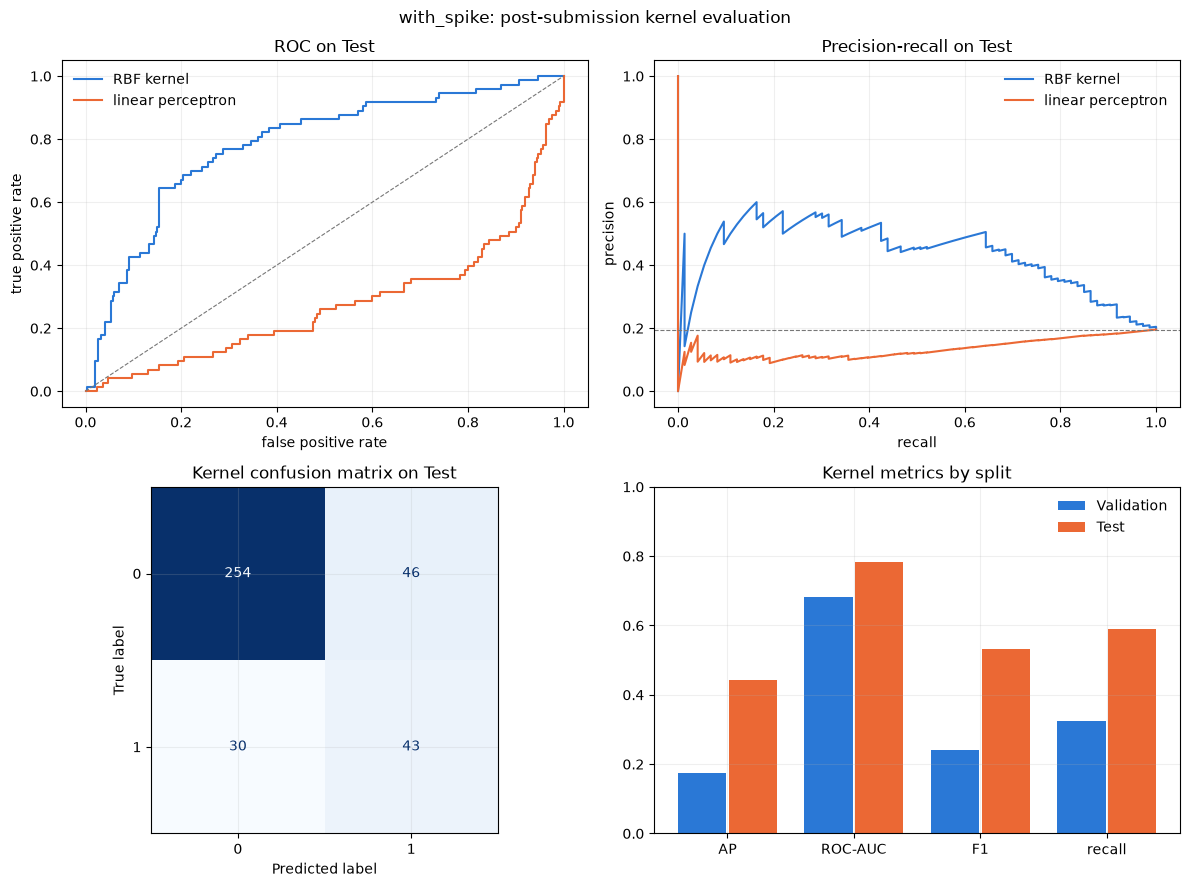

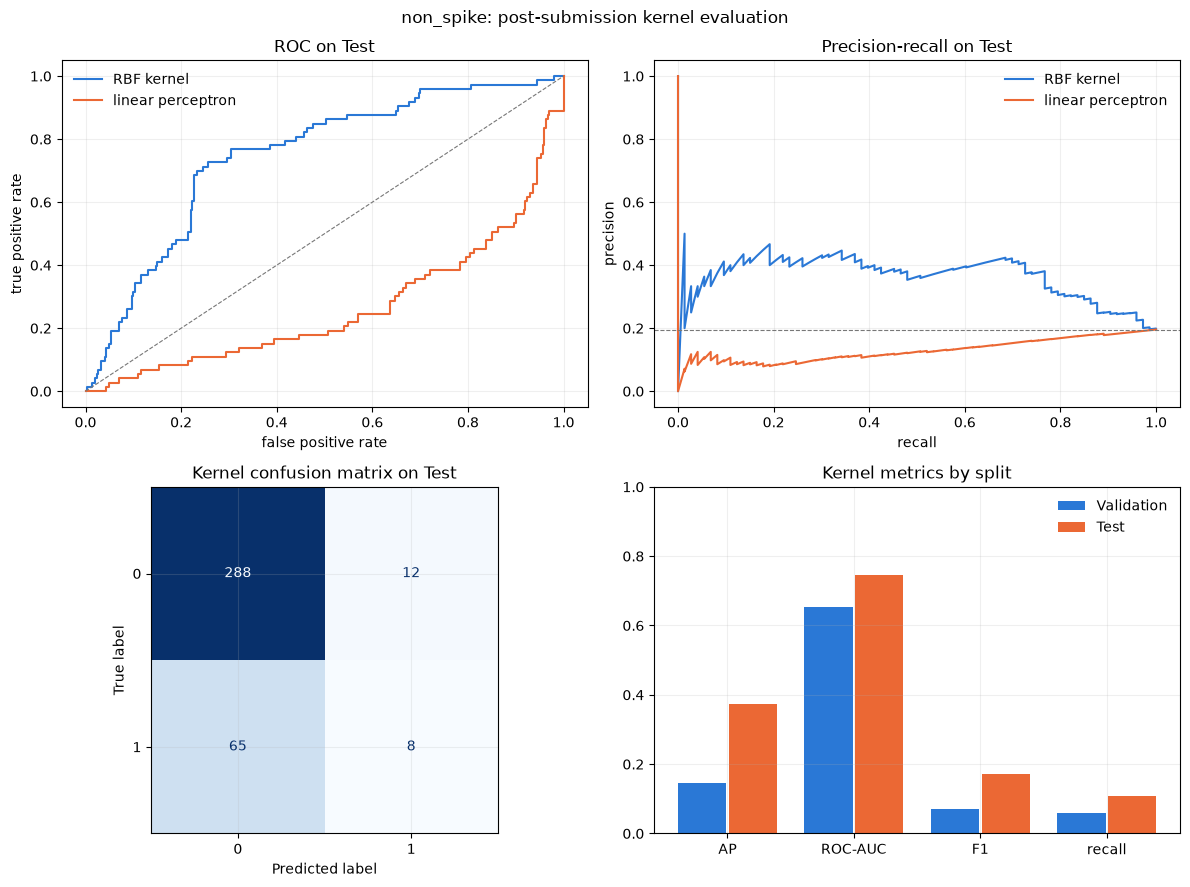

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve

for variant in ("with_spike", "non_spike"):
    run = experiment / variant / "classification" / "kernel_perceptron"
    kernel = pd.read_csv(run / "test_predictions.csv")
    linear = pd.read_csv(root / "outputs" / "modeling" / variant / "classification" / "perceptron" / "test_predictions.csv")
    assert kernel["Date"].equals(linear["Date"]) and (kernel["target"].to_numpy() == linear["target"].to_numpy()).all()
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for frame, label, color in ((kernel, "RBF kernel", "#2a78d6"), (linear, "linear perceptron", "#eb6834")):
        fpr, tpr, _ = roc_curve(frame["target"], frame["raw_score"])
        precision, recall, _ = precision_recall_curve(frame["target"], frame["raw_score"])
        axes[0, 0].plot(fpr, tpr, label=label, color=color)
        axes[0, 1].plot(recall, precision, label=label, color=color)
    axes[0, 0].plot([0, 1], [0, 1], linestyle="--", color="#777777", linewidth=0.8)
    axes[0, 1].axhline(kernel["target"].mean(), linestyle="--", color="#777777", linewidth=0.8)
    axes[0, 0].set(title="ROC on Test", xlabel="false positive rate", ylabel="true positive rate")
    axes[0, 1].set(title="Precision-recall on Test", xlabel="recall", ylabel="precision")
    ConfusionMatrixDisplay.from_predictions(kernel["target"], kernel["final_prediction"], labels=[0, 1],
                                            colorbar=False, ax=axes[1, 0], cmap="Blues")
    axes[1, 0].set_title("Kernel confusion matrix on Test")
    validation = json.loads((run / "validation_metrics.json").read_text(encoding="utf-8"))
    test = json.loads((run / "test_metrics.json").read_text(encoding="utf-8"))
    metric_names = ("average_precision", "roc_auc", "f1", "recall")
    x = range(len(metric_names))
    axes[1, 1].bar([i - 0.2 for i in x], [validation[m]["value"] for m in metric_names], 0.38,
                   label="Validation", color="#2a78d6")
    axes[1, 1].bar([i + 0.2 for i in x], [test[m]["value"] for m in metric_names], 0.38,
                   label="Test", color="#eb6834")
    axes[1, 1].set_xticks(list(x), ["AP", "ROC-AUC", "F1", "recall"])
    axes[1, 1].set(title="Kernel metrics by split", ylim=(0, 1))
    for ax in (axes[0, 0], axes[0, 1], axes[1, 1]):
        ax.legend(frameon=False)
    for ax in axes.flat:
        ax.grid(alpha=0.2)
    fig.suptitle(f"{variant}: post-submission kernel evaluation")
    fig.tight_layout()
    plt.show()


### 11.3 ช่วงความเชื่อมั่นและผลแยกช่วงบน Test

ตารางอันดับเสริมมีช่วง 95% จาก moving-block bootstrap ก้อน 20 วัน 2,000 รอบ ผลแยกช่วง spike ใช้ป้ายช่วงจากคำทำนายที่บันทึกในงานเดิมแล้วและจับคู่ด้วยวันและ label; ไม่มีการฝึกหรือเลือกค่าใหม่จาก Test ค่า AP ของสองช่วงเทียบตรง ๆ ไม่ได้เพราะสัดส่วน positive ต่างกันมาก


with_spike: supplementary Test leaderboard with 95% moving-block intervals


,ap_rank,model,study,average_precision,average_precision_low,average_precision_high,roc_auc,roc_auc_low,roc_auc_high,recall,f1
0,1,mlp,locked study,0.5991,0.2605,0.7603,0.7930,0.6103,0.9031,0.4932,0.5714
1,2,random_forest,locked study,0.5775,0.2366,0.7393,0.7866,0.5922,0.8920,0.4247,0.5000
2,3,svm,locked study,0.5716,0.2402,0.7438,0.7835,0.5935,0.8955,0.3973,0.4874
3,4,gaussian_nb,locked study,0.5538,0.2390,0.7289,0.7703,0.5749,0.8838,0.6164,0.5806
4,5,slp,locked study,0.5536,0.2473,0.7470,0.7798,0.5865,0.8954,0.4247,0.5041
5,6,logistic,locked study,0.5518,0.2482,0.7452,0.7822,0.5936,0.8978,0.4384,0.5203
6,7,knn,locked study,0.5472,0.2187,0.7309,0.7847,0.6241,0.8634,0.4795,0.5512
7,8,baseline_persistence,locked study,0.5365,0.1589,0.7246,0.7255,0.5280,0.8308,0.5068,0.4933
8,9,gradient_boosting,locked study,0.5332,0.2223,0.7096,0.7665,0.5798,0.8803,0.3699,0.4390
9,10,xgboost,locked study,0.5305,0.2021,0.7067,0.7716,0.5844,0.8839,0.3836,0.4553


non_spike: supplementary Test leaderboard with 95% moving-block intervals


,ap_rank,model,study,average_precision,average_precision_low,average_precision_high,roc_auc,roc_auc_low,roc_auc_high,recall,f1
0,1,gaussian_nb,locked study,0.5884,0.2441,0.7462,0.7779,0.5735,0.8913,0.7260,0.5824
1,2,xgboost,locked study,0.5823,0.2509,0.7436,0.7887,0.6017,0.8948,0.4795,0.5469
2,3,svm,locked study,0.5805,0.2446,0.7504,0.7853,0.5967,0.8990,0.3425,0.4587
3,4,gradient_boosting,locked study,0.5653,0.2460,0.7310,0.7861,0.6087,0.8920,0.2603,0.3762
4,5,mlp,locked study,0.5639,0.2507,0.7235,0.7894,0.5922,0.8906,0.4384,0.5039
5,6,logistic,locked study,0.5510,0.2472,0.7391,0.7782,0.5841,0.8940,0.4247,0.5041
6,7,stacking,locked study,0.5499,0.2440,0.7150,0.7890,0.6135,0.8828,0.4521,0.4853
7,8,adaboost,locked study,0.5443,0.2261,0.7297,0.7735,0.5788,0.8899,0.4110,0.5000
8,9,knn,locked study,0.5389,0.2514,0.7067,0.8008,0.6595,0.8698,0.3425,0.4237
9,10,baseline_persistence,locked study,0.5365,0.1589,0.7246,0.7255,0.5280,0.8308,0.5068,0.4933


,variant,segment,rows,positives,average_precision,roc_auc,precision,recall,specificity,f1,accuracy,confusion_matrix
0,with_spike,spike_affected,54,38,0.8809,0.7138,0.8519,0.6053,0.7500,0.7077,0.6481,"[[12, 4], [15, 23]]"
1,with_spike,non_spike,319,35,0.2709,0.7241,0.3226,0.5714,0.8521,0.4124,0.8213,"[[242, 42], [15, 20]]"
2,non_spike,spike_affected,54,38,0.9101,0.7862,1.0000,0.1053,1.0000,0.1905,0.3704,"[[16, 0], [34, 4]]"
3,non_spike,non_spike,319,35,0.2329,0.6910,0.2500,0.1143,0.9577,0.1569,0.8652,"[[272, 12], [31, 4]]"


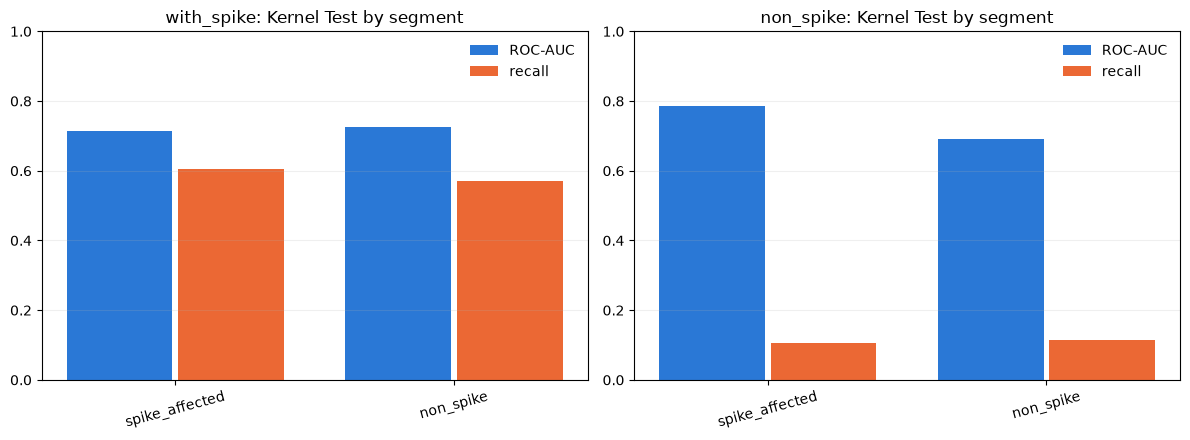

In [19]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
report = root / "outputs" / "experiments" / "kernel_perceptron" / "report"
for variant in ("with_spike", "non_spike"):
    board = pd.read_csv(report / f"leaderboard_test_{variant}.csv")
    fields = ["ap_rank", "model", "study", "average_precision", "average_precision_low", "average_precision_high",
              "roc_auc", "roc_auc_low", "roc_auc_high", "recall", "f1"]
    print(f"{variant}: supplementary Test leaderboard with 95% moving-block intervals")
    display(board[fields].round(4))
segments = pd.read_csv(report / "segmented_metrics.csv")
display(segments[["variant", "segment", "rows", "positives", "average_precision", "roc_auc",
                  "precision", "recall", "specificity", "f1", "accuracy", "confusion_matrix"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, variant in zip(axes, ("with_spike", "non_spike")):
    frame = segments[segments["variant"] == variant]
    x = np.arange(len(frame))
    ax.bar(x - 0.2, frame["roc_auc"], 0.38, label="ROC-AUC", color="#2a78d6")
    ax.bar(x + 0.2, frame["recall"], 0.38, label="recall", color="#eb6834")
    ax.set_xticks(x, frame["segment"], rotation=15)
    ax.set(title=f"{variant}: Kernel Test by segment", ylim=(0, 1))
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False)
fig.tight_layout()
plt.show()


### 11.4 ผลต่างแบบ paired บน Test

ผลต่างเป็น Kernel ลบ Perceptron เส้นตรงหรือโมเดล headline ที่ล็อกไว้ก่อนเปิด Test ช่วงที่คร่อมศูนย์ยังสรุปว่าดีกว่าไม่ได้ และผล Kernel เป็นการทดลองหลังเห็นผล Test ของงานเดิมแล้ว


In [20]:
rows = []
for variant in ("with_spike", "non_spike"):
    result = json.loads((report / f"bootstrap_test_{variant}.json").read_text(encoding="utf-8"))
    for reference, fields in result["paired_delta_vs_kernel"].items():
        for metric in ("average_precision", "roc_auc", "f1", "recall"):
            value = fields[metric]
            rows.append({"variant": variant, "reference": reference, "metric": metric,
                         "kernel minus reference": value["point"], "95% low": value["low"],
                         "95% high": value["high"], "excludes zero": value["excludes_zero"]})
display(pd.DataFrame(rows).round(4))


,variant,reference,metric,kernel minus reference,95% low,95% high,excludes zero
0,with_spike,linear_perceptron,average_precision,0.3042,0.1030,0.4360,True
1,with_spike,linear_perceptron,roc_auc,0.5077,0.2068,0.6723,True
2,with_spike,linear_perceptron,f1,0.4732,0.1898,0.6000,True
3,with_spike,linear_perceptron,recall,0.5479,0.2500,0.6667,True
4,with_spike,locked_headline,average_precision,-0.1575,-0.3320,0.0648,False
5,with_spike,locked_headline,roc_auc,-0.0104,-0.1060,0.1054,False
6,with_spike,locked_headline,f1,-0.0406,-0.1832,0.1759,False
7,with_spike,locked_headline,recall,0.0959,-0.0898,0.3572,False
8,non_spike,linear_perceptron,average_precision,0.2400,0.0784,0.3730,True
9,non_spike,linear_perceptron,roc_auc,0.4844,0.1874,0.6588,True


## 12. ผลติดตามหลังนำเสนอ: Transfer learning บน Test และ holdout

ผลนี้อ่านจาก [`outputs/experiments/transfer_learning/test/`](../outputs/experiments/transfer_learning/test/) เท่านั้น **ไม่มีการโหลด Test ใน notebook**

- **เปิด Test ครั้งเดียวเมื่อ 2026-10-25:** ทำหลังเจ้าของโปรเจกต์อนุมัติ ด้วย config และ checkpoint ที่ล็อก hash ไว้ใน `decision.json` และมี [`test_receipt.json`](../outputs/experiments/transfer_learning/test_receipt.json) ระบุ `post_hoc: true`
- **ผลเป็น post-hoc:** Test เคยถูกเปิดในงานหลักแล้ว จึงไม่ใช่การเปรียบเทียบแบบ blind และไม่ใช้เปลี่ยน leaderboard หรือ headline เดิม
- **Holdout ใหม่:** QQQ ช่วง 2026-08-24..2026-10-16 รวม 39 วัน ดึงหลัง snapshot เดิม จึง blind จริง แต่มีวันผันผวนสูงเพียง 2 วัน
- **การตรวจซ้ำ:** คำนวณ AP, ROC-AUC และ confusion matrix ซ้ำจาก CSV ด้วย scikit-learn แล้วตรงกับ JSON (ต่าง ≤ 2.2×10⁻¹⁶)

รายละเอียดอยู่ที่ [บันทึกการทดลอง](../docs/models/transfer_learning/EXPERIMENT.md)

### 12.1 อันดับบน Test รวม arm ใหม่

ใส่ arm ใหม่ทั้ง 8 ตัวลงใน leaderboard Test เดิมเพื่อเทียบอันดับ AP เท่านั้น (`study=post-presentation`) ช่วงความเชื่อมั่นอยู่ในหัวข้อ 12.3

In [21]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
tl = root / "outputs" / "experiments" / "transfer_learning"
ARMS = ["T-scratch", "T-ssl", "T-full", "T-probe", "G-scratch", "G-ssl", "G-full", "G-probe"]
HUE = {"T": "#2a78d6", "G": "#eb6834", "mlp": "#1baf7a", "baseline_persistence": "#8a8984"}

receipt = json.loads((tl / "test_receipt.json").read_text(encoding="utf-8"))
assert receipt["status"] == "completed" and receipt["post_hoc"] is True and receipt["test_rows"] == 373
for variant in ("with_spike", "non_spike"):
    original = pd.read_csv(root / "outputs" / "modeling" / "final" / variant / "leaderboard_classification.csv")
    fields = ["model", "kind", "average_precision", "roc_auc", "f1", "recall", "precision"]
    original = original[fields].copy()
    original["study"] = "locked study"
    metrics = json.loads((tl / "test" / variant / "test_metrics.json").read_text(encoding="utf-8"))["models"]
    new = pd.DataFrame([{"model": arm, "kind": "model", "study": "post-presentation",
                         **{f: metrics[arm]["point"][f] for f in fields[2:]}} for arm in ARMS])
    board = pd.concat([original, new], ignore_index=True).sort_values("average_precision", ascending=False).reset_index(drop=True)
    board.insert(0, "AP rank", board["average_precision"].rank(method="min", ascending=False).astype(int))
    print(f"{variant}: Test ranking with the eight transfer-learning arms (post-hoc)")
    display(board.round(4))
    print("T-full confusion matrix [[TN, FP], [FN, TP]]:", metrics["T-full"]["point"]["confusion_matrix"])


with_spike: Test ranking with the eight transfer-learning arms (post-hoc)


,AP rank,model,kind,average_precision,roc_auc,f1,recall,precision,study
0,1,mlp,model,0.5991,0.7930,0.5714,0.4932,0.6792,locked study
1,2,G-scratch,model,0.5798,0.7835,0.5672,0.7808,0.4453,post-presentation
2,3,random_forest,model,0.5775,0.7866,0.5000,0.4247,0.6078,locked study
3,4,G-probe,model,0.5728,0.7917,0.5128,0.8219,0.3727,post-presentation
4,5,svm,model,0.5716,0.7835,0.4874,0.3973,0.6304,locked study
5,6,G-ssl,model,0.5669,0.7835,0.5130,0.8082,0.3758,post-presentation
6,7,gaussian_nb,model,0.5538,0.7703,0.5806,0.6164,0.5488,locked study
7,8,slp,model,0.5536,0.7798,0.5041,0.4247,0.6200,locked study
8,9,logistic,model,0.5518,0.7822,0.5203,0.4384,0.6400,locked study
9,10,G-full,model,0.5486,0.7806,0.5085,0.8219,0.3681,post-presentation


T-full confusion matrix [[TN, FP], [FN, TP]]: [[216, 84], [24, 49]]
non_spike: Test ranking with the eight transfer-learning arms (post-hoc)


,AP rank,model,kind,average_precision,roc_auc,f1,recall,precision,study
0,1,G-scratch,model,0.6183,0.7923,0.5221,0.8082,0.3856,post-presentation
1,2,G-probe,model,0.6041,0.7945,0.4979,0.8219,0.3571,post-presentation
2,3,G-ssl,model,0.6020,0.7846,0.4819,0.8219,0.3409,post-presentation
3,4,gaussian_nb,model,0.5884,0.7779,0.5824,0.7260,0.4862,locked study
4,5,xgboost,model,0.5823,0.7887,0.5469,0.4795,0.6364,locked study
5,6,svm,model,0.5805,0.7853,0.4587,0.3425,0.6944,locked study
6,7,G-full,model,0.5739,0.7905,0.4858,0.8219,0.3448,post-presentation
7,8,gradient_boosting,model,0.5653,0.7861,0.3762,0.2603,0.6786,locked study
8,9,mlp,model,0.5639,0.7894,0.5039,0.4384,0.5926,locked study
9,10,logistic,model,0.5510,0.7782,0.5041,0.4247,0.6200,locked study


T-full confusion matrix [[TN, FP], [FN, TP]]: [[148, 152], [20, 53]]


**อ่านตาราง:**

- **ผลบน Test เป็นไปตาม Validation:** โมเดลหลัก `T-full` อยู่อันดับ 14 จาก 16 ทั้งสอง variant ส่วน GRU อยู่กลุ่มบน (`G-scratch` ได้อันดับ 2 ใน with_spike และอันดับ 1 ใน non_spike)
- **อันดับ 1 ของ GRU ใน non_spike ไม่ได้แปลว่าดีกว่าจริง:** ส่วนต่างกับโมเดลอื่นในกลุ่มบนเล็กกว่าความไม่แน่นอนมาก และ GRU เป็น ablation ที่ไม่ได้ล็อกไว้เป็นตัวแทน

### 12.2 กราฟผลบน Test

PR curve เทียบ `T-full`, `T-scratch`, `G-scratch`, MLP และ persistence บน 373 วันชุดเดียวกัน พร้อม confusion matrix ของ `T-full` และ `G-scratch` ที่ความน่าจะเป็น > 0.5 เส้นประคือสัดส่วน positive ของ Test (0.196)

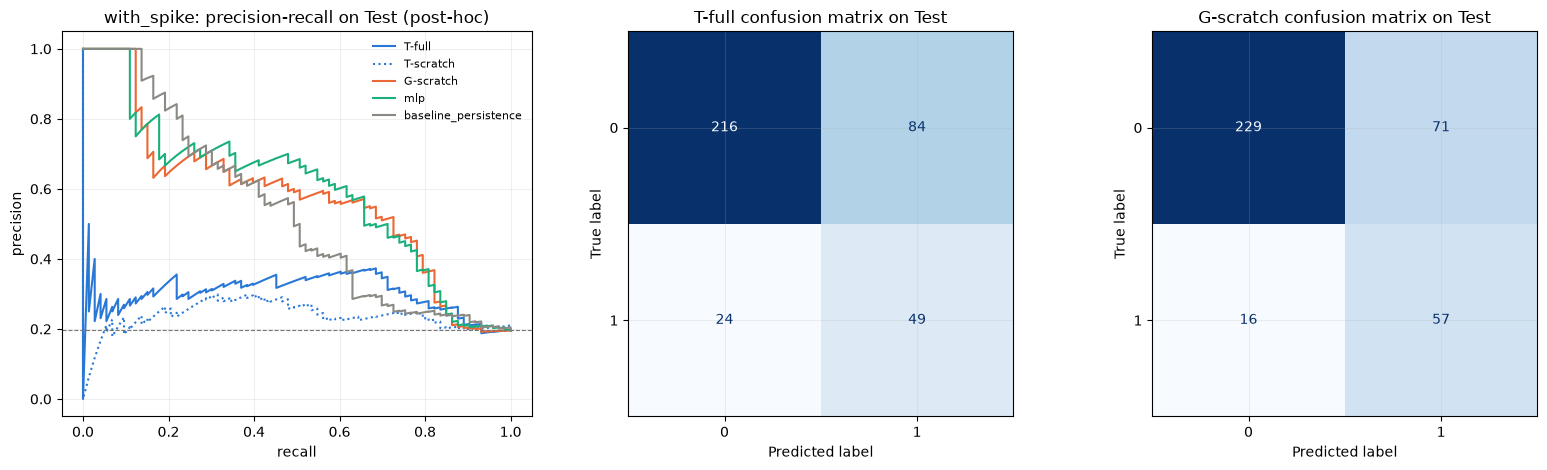

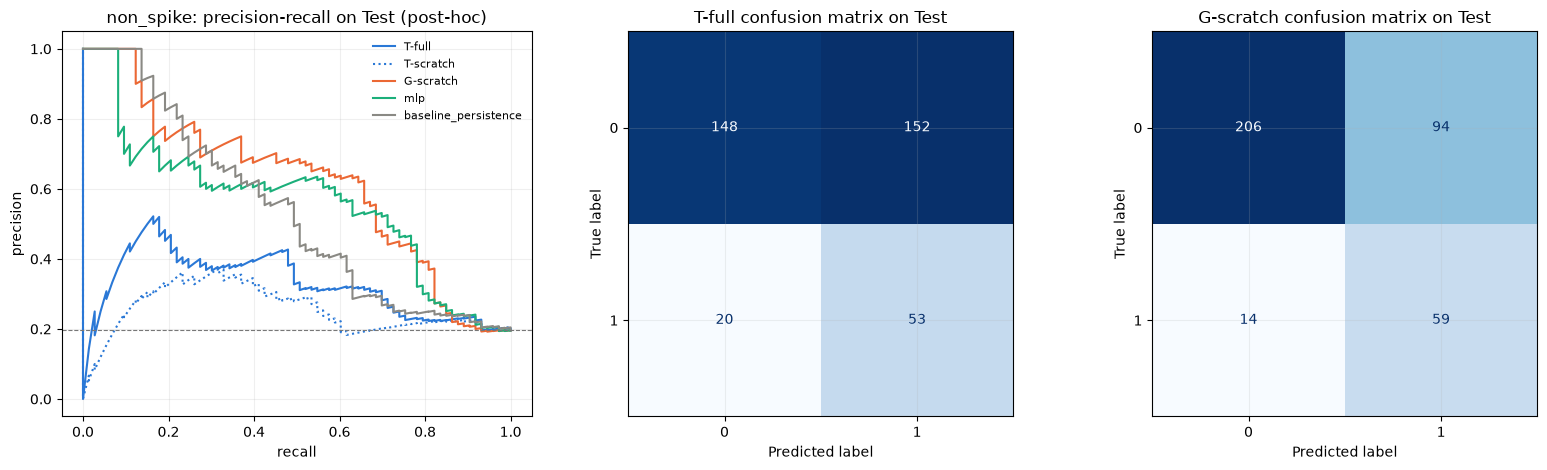

In [22]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
tl = root / "outputs" / "experiments" / "transfer_learning"
ARMS = ["T-scratch", "T-ssl", "T-full", "T-probe", "G-scratch", "G-ssl", "G-full", "G-probe"]
HUE = {"T": "#2a78d6", "G": "#eb6834", "mlp": "#1baf7a", "baseline_persistence": "#8a8984"}
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

style = {"T-full": ("#2a78d6", "-"), "T-scratch": ("#2a78d6", ":"), "G-scratch": ("#eb6834", "-"),
         "mlp": ("#1baf7a", "-"), "baseline_persistence": ("#8a8984", "-")}
for variant in ("with_spike", "non_spike"):
    frames = {name: pd.read_csv(tl / "test" / variant / f"{name}_test_predictions.csv") for name in style}
    dates = frames["T-full"]["Date"]
    assert all(f["Date"].equals(dates) and f["target"].equals(frames["T-full"]["target"]) for f in frames.values())
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    for name, frame in frames.items():
        precision, recall, _ = precision_recall_curve(frame["target"], frame["raw_score"])
        axes[0].plot(recall, precision, color=style[name][0], linestyle=style[name][1], label=name)
    axes[0].axhline(frames["T-full"]["target"].mean(), color="#777777", linestyle="--", linewidth=0.8)
    axes[0].set(title=f"{variant}: precision-recall on Test (post-hoc)", xlabel="recall", ylabel="precision")
    axes[0].legend(frameon=False, fontsize=8)
    for ax, name in zip(axes[1:], ("T-full", "G-scratch")):
        ConfusionMatrixDisplay.from_predictions(frames[name]["target"], frames[name]["final_prediction"], labels=[0, 1],
                                                colorbar=False, ax=ax, cmap="Blues")
        ax.set_title(f"{name} confusion matrix on Test")
    for ax in axes:
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()


**อ่านกราฟ:**

- **PR curve:** ของ Transformer ต่ำกว่า MLP และ persistence ตลอดช่วง recall ส่วน GRU อยู่ระดับเดียวกับ MLP
- **Confusion matrix:** `G-scratch` จับวันผันผวนสูงได้มากกว่า MLP (recall สูงกว่า) แต่แลกกับการเตือนผิดมากขึ้น เพราะความน่าจะเป็นถูกถ่วงด้วย `pos_weight` และใช้เกณฑ์ 0.5 คงที่

### 12.3 ผลต่างแบบ paired บน Test และผลบน holdout

ผลต่าง AP คำนวณแบบ paired บนวันเดียวกันด้วย moving-block bootstrap ก้อน 20 วัน 2,000 รอบ ตารางที่สองแสดง holdout 39 วัน ซึ่งเป็นหลักฐานเชิงพรรณนาเท่านั้นเพราะมีวันผันผวนสูง 2 วัน

,variant,comparison,AP difference,95% low,95% high,excludes zero
0,with_spike,T-full - T-scratch,0.0695,0.0132,0.1885,True
1,with_spike,T-full - T-ssl,0.0130,-0.0195,0.0404,False
2,with_spike,T-full - mlp,-0.2895,-0.3975,-0.0519,True
3,with_spike,T-full - baseline_persistence,-0.2269,-0.3601,0.0492,False
4,with_spike,G-full - G-scratch,-0.0312,-0.0958,0.0972,False
5,with_spike,G-scratch - mlp,-0.0193,-0.0597,0.0557,False
6,with_spike,G-scratch - baseline_persistence,0.0434,-0.0575,0.1637,False
7,non_spike,T-full - T-scratch,0.0735,-0.0034,0.2047,False
8,non_spike,T-full - T-ssl,0.0172,-0.0085,0.0266,False
9,non_spike,T-full - mlp,-0.2339,-0.3221,-0.0476,True


,variant,model,rows,positives,AP,ROC-AUC,confusion matrix
0,with_spike,T-full,39,2,0.0531,0.2973,"[[32, 5], [2, 0]]"
1,with_spike,T-scratch,39,2,0.0733,0.5000,"[[37, 0], [2, 0]]"
2,with_spike,G-scratch,39,2,1.0000,1.0000,"[[37, 0], [1, 1]]"
3,with_spike,G-full,39,2,1.0000,1.0000,"[[37, 0], [1, 1]]"
4,with_spike,mlp,39,2,1.0000,1.0000,"[[37, 0], [2, 0]]"
5,with_spike,baseline_persistence,39,2,0.1381,0.7432,"[[37, 0], [2, 0]]"
6,non_spike,T-full,39,2,0.0464,0.1757,"[[24, 13], [2, 0]]"
7,non_spike,T-scratch,39,2,0.0425,0.0946,"[[10, 27], [2, 0]]"
8,non_spike,G-scratch,39,2,1.0000,1.0000,"[[37, 0], [0, 2]]"
9,non_spike,G-full,39,2,1.0000,1.0000,"[[36, 1], [0, 2]]"


with_spike holdout: scores on the two high-volatility days


,Date,target,T-full,G-scratch,mlp,baseline_persistence
37,2026-10-15,1,0.3303,0.3945,0.3014,0.1450
38,2026-10-16,1,0.3452,0.6000,0.4093,0.1665


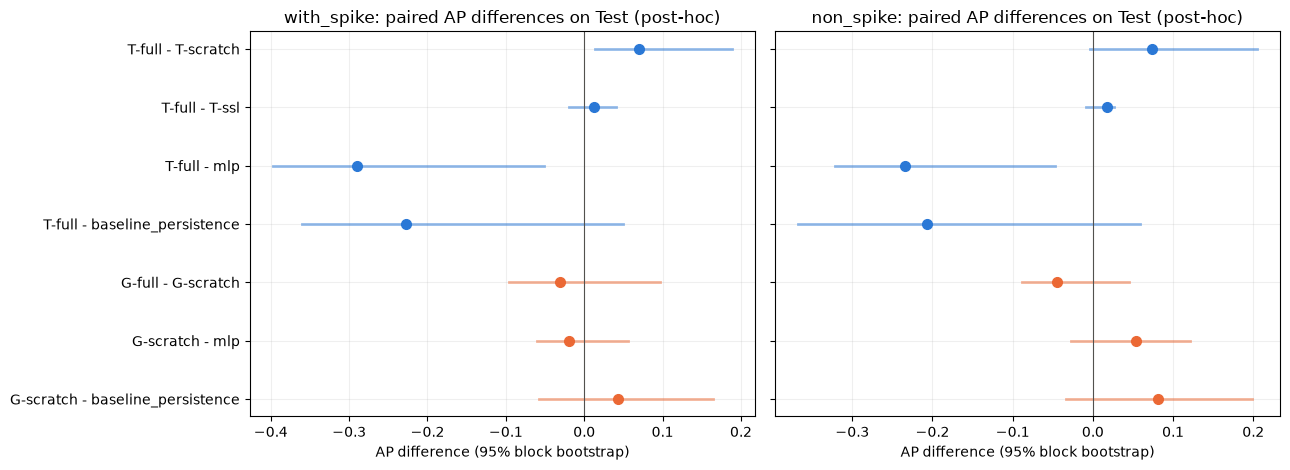

In [23]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
tl = root / "outputs" / "experiments" / "transfer_learning"
ARMS = ["T-scratch", "T-ssl", "T-full", "T-probe", "G-scratch", "G-ssl", "G-full", "G-probe"]
HUE = {"T": "#2a78d6", "G": "#eb6834", "mlp": "#1baf7a", "baseline_persistence": "#8a8984"}

extra = json.loads((tl / "report" / "gru_vs_baselines.json").read_text(encoding="utf-8"))
rows, holdout = [], []
for variant in ("with_spike", "non_spike"):
    metrics = json.loads((tl / "test" / variant / "test_metrics.json").read_text(encoding="utf-8"))
    pairs = {**metrics["paired_ap_differences"], **extra[variant]["test"]}
    for name in ("T-full - T-scratch", "T-full - T-ssl", "T-full - mlp", "T-full - baseline_persistence",
                 "G-full - G-scratch", "G-scratch - mlp", "G-scratch - baseline_persistence"):
        d = pairs[name]
        rows.append({"variant": variant, "comparison": name, "AP difference": d["point"], "95% low": d["low"],
                     "95% high": d["high"], "excludes zero": d["excludes_zero"]})
    hold = json.loads((tl / "test" / variant / "holdout_metrics.json").read_text(encoding="utf-8"))
    for model in ("T-full", "T-scratch", "G-scratch", "G-full", "mlp", "baseline_persistence"):
        p = hold["models"][model]["point"]
        holdout.append({"variant": variant, "model": model, "rows": hold["rows"], "positives": hold["positives"],
                        "AP": p["average_precision"], "ROC-AUC": p["roc_auc"], "confusion matrix": p["confusion_matrix"]})
table = pd.DataFrame(rows)
display(table.round(4))
display(pd.DataFrame(holdout).round(4))
days = pd.read_csv(tl / "test" / "with_spike" / "holdout_predictions.csv")
print("with_spike holdout: scores on the two high-volatility days")
display(days[days["target"] == 1][["Date", "target", "T-full", "G-scratch", "mlp", "baseline_persistence"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, variant in zip(axes, ("with_spike", "non_spike")):
    part = table[table["variant"] == variant].reset_index(drop=True)
    for i, r in part.iterrows():
        color = HUE["T"] if r["comparison"].startswith("T-") else HUE["G"]
        ax.plot([r["95% low"], r["95% high"]], [i, i], color=color, linewidth=2, alpha=0.5)
        ax.plot(r["AP difference"], i, "o", color=color, markersize=7)
    ax.axvline(0, color="#52514e", linewidth=0.8)
    ax.set_yticks(range(len(part)), part["comparison"])
    ax.set(title=f"{variant}: paired AP differences on Test (post-hoc)", xlabel="AP difference (95% block bootstrap)")
    ax.grid(alpha=0.2)
axes[0].invert_yaxis()  # shared y: invert once
fig.tight_layout()
plt.show()


**ข้อสรุปของการทดลองเสริม (ตอบคำถามอาจารย์):**

1. **Pretraining ช่วย Transformer แต่ยังไม่พอใช้งาน:** `T-full − T-scratch` = +0.070 [+0.013, +0.189] บน Test ของ with_spike แต่ `T-full` ยังแย่กว่า MLP ชัดเจน (−0.290 [−0.398, −0.052])
2. **GRU เสมอกับ MLP:** ทุกคู่ `G − MLP` คร่อมศูนย์ และ pretraining ไม่ช่วย GRU ฟีเจอร์ 8 ตัวที่สรุปประวัติย้อนหลังไว้แล้วจึงเพียงพอ ลำดับ 60 วันไม่ได้เพิ่มข้อมูลที่โมเดลแบบวันเดียวยังไม่มี
3. **Holdout สอดคล้องกัน:** GRU และ MLP จัดวันผันผวนสูงทั้ง 2 วันไว้อันดับบนสุด ส่วน Transformer จัดไว้ต่ำ แต่ 2 วันน้อยเกินกว่าจะสรุปทางสถิติ
4. **ข้อสรุปจำกัดอยู่ในขอบเขตที่ทดลอง:** ฟีเจอร์ 8 ตัวเดิม, ETF 10 ตัว (ย้อนหลังได้แค่ 10 ปี) และขนาดโมเดลที่ตั้งไว้ล่วงหน้า การปรับ Transformer หลังเห็นผล (เช่น ใช้วันสุดท้ายแทนค่าเฉลี่ยทั้ง window) ต้องทดสอบกับข้อมูลอนาคตชุดใหม่

## 13. ผลติดตามหลังนำเสนอ: Log-HAR บน Test และ holdout

ผลนี้อ่านจาก [`outputs/experiments/log_har/test/`](../outputs/experiments/log_har/test/) เท่านั้น **ไม่มีการโหลด Test ใน notebook**

- **เปิด Test ครั้งเดียวเมื่อ 2026-10-25** หลังเจ้าของโปรเจกต์อนุมัติ ด้วยโมเดลและ κ ที่ล็อก hash ไว้ใน `decision.json` และมี [`test_receipt.json`](../outputs/experiments/log_har/test_receipt.json) ระบุ `post_hoc: true` เพราะ Test เคยถูกเปิดในงานหลักแล้ว จึงไม่ใช่การเปรียบเทียบแบบ blind และไม่ใช้เปลี่ยน leaderboard หรือ headline เดิม
- **Holdout:** QQQ 39 วันหลัง snapshot (2026-08-24 ถึง 2026-10-16) ซึ่งไม่เคยถูกใช้มาก่อน target เป็นค่าต่อเนื่องทุกวัน จึงใช้ได้ดีกว่าตอน classification ที่มีวัน positive เพียง 2 วัน แต่ยังสั้นและไม่มีช่วง spike
- **การตรวจซ้ำ:** คำนวณ RMSE, MAE และ R² ซ้ำจาก CSV ด้วย scikit-learn แล้วตรงกับ JSON (ต่าง ≤ 2.2×10⁻¹⁶)

รายละเอียดอยู่ที่ [บันทึกการทดลอง](../docs/models/log_har/EXPERIMENT.md)

### 13.1 อันดับบน Test รวม arm ใหม่

ใส่ arm ใหม่ทั้ง 4 ตัวลงใน leaderboard regression บน Test เดิม เพื่อเทียบอันดับ RMSE เท่านั้น (`study=post-presentation`)

In [24]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
lh = root / "outputs" / "experiments" / "log_har"
ARMS = ["H3-qqq", "HX-qqq", "HX-pool", "HX-prior"]
COLOR = {"HX-prior": "#2a78d6", "HX-qqq": "#1baf7a", "H3-qqq": "#9085e9", "HX-pool": "#2a78d6",
         "elastic_net": "#eb6834", "multiple_linear": "#8a8984", "target": "#0b0b0b"}

receipt = json.loads((lh / "test_receipt.json").read_text(encoding="utf-8"))
assert receipt["status"] == "completed" and receipt["post_hoc"] is True and receipt["test_rows"] == 373
for variant in ("with_spike", "non_spike"):
    original = pd.read_csv(root / "outputs" / "modeling" / "final" / variant / "leaderboard_regression.csv")
    original = original[["model", "kind", "rmse", "mae", "r2"]].copy()
    original["study"] = "locked study"
    metrics = json.loads((lh / "test" / variant / "test_metrics.json").read_text(encoding="utf-8"))
    rows = {row["model"]: row for row in metrics["leaderboard"]}
    for model, rmse in zip(original["model"], original["rmse"]):
        assert abs(rows[model]["rmse"] - rmse) < 1e-12  # same Test predictions as the locked study
    new = pd.DataFrame([{"model": arm, "kind": "model", "study": "post-presentation", "rmse": rows[arm]["rmse"],
                         "mae": rows[arm]["mae"], "r2": rows[arm]["r2"]} for arm in ARMS])
    board = pd.concat([original, new], ignore_index=True).sort_values("rmse").reset_index(drop=True)
    board.insert(0, "RMSE rank", board["rmse"].rank(method="min").astype(int))
    board["qlike"] = board["model"].map(lambda m: rows[m]["qlike"])
    print(f"{variant}: Test ranking with the four log-HAR arms (post-hoc)")
    display(board.round(4))


with_spike: Test ranking with the four log-HAR arms (post-hoc)


,RMSE rank,model,kind,rmse,mae,r2,study,qlike
0,1,HX-qqq,model,0.1076,0.0680,0.3921,post-presentation,0.5800
1,2,HX-pool,model,0.1090,0.0686,0.3761,post-presentation,0.5664
2,2,HX-prior,model,0.1090,0.0686,0.3761,post-presentation,0.5664
3,4,multiple_linear,model,0.1158,0.0722,0.2959,locked study,0.6084
4,5,elastic_net,model,0.1174,0.0731,0.2758,locked study,0.5597
5,6,H3-qqq,model,0.1293,0.0809,0.1214,post-presentation,0.7202
6,7,simple_linear,model,0.1356,0.0834,0.0347,locked study,0.7036
7,8,baseline_train_mean,baseline,0.1380,0.0882,-0.0006,locked study,0.8808
8,9,polynomial,model,0.1401,0.0861,-0.0314,locked study,0.7024
9,10,baseline_persistence,baseline,0.1502,0.0936,-0.1855,locked study,1.8298


non_spike: Test ranking with the four log-HAR arms (post-hoc)


,RMSE rank,model,kind,rmse,mae,r2,study,qlike
0,1,HX-qqq,model,0.1055,0.0661,0.4155,post-presentation,0.5914
1,2,HX-prior,model,0.1091,0.0679,0.3753,post-presentation,0.5893
2,3,HX-pool,model,0.1091,0.0679,0.3752,post-presentation,0.5862
3,4,polynomial,model,0.1142,0.0743,0.3155,locked study,0.6751
4,5,multiple_linear,model,0.1180,0.0721,0.2684,locked study,0.6675
5,6,elastic_net,model,0.1230,0.0736,0.2059,locked study,0.6540
6,7,H3-qqq,model,0.1276,0.0781,0.1446,post-presentation,0.7432
7,8,simple_linear,model,0.1372,0.0827,0.0114,locked study,1.6781
8,9,baseline_train_mean,baseline,0.1400,0.0844,-0.0298,locked study,1.0997
9,10,baseline_persistence,baseline,0.1502,0.0936,-0.1855,locked study,1.8298


**อ่านตาราง:** บน Test อันดับกลับข้างจาก Validation `HX-qqq` ได้ RMSE ต่ำสุด (0.1076 และ 0.1055) และ `HX-prior` อยู่อันดับ 2 ทั้งสอง variant ขณะที่ Elastic Net อยู่อันดับ 5 และ 6 R² ของ Log-HAR อยู่ราว 0.38 ถึง 0.42 สูงกว่าทุกโมเดล regression ในงานหลัก (Elastic Net 0.276 และ 0.206) ส่วน QLIKE ของ Log-HAR ดีกว่า Elastic Net ใน non_spike แต่ใกล้กันใน with_spike

### 13.2 คำทำนายตามเวลาและผลแยกช่วงตลาด

1. **คำทำนายบน Test ตามเวลา:** ค่าจริงเทียบกับ `HX-prior`, `HX-qqq` และ Elastic Net พื้นที่แรเงาคือวันในช่วงรอบวัน spike (54 วัน) ซึ่งเป็นป้ายจากงานหลัก
2. **RMSE แยกช่วงตลาด:** ช่วงปกติ 319 วันและช่วงรอบวัน spike 54 วัน
3. **Holdout 39 วัน:** ค่าจริงเทียบกับคำทำนาย

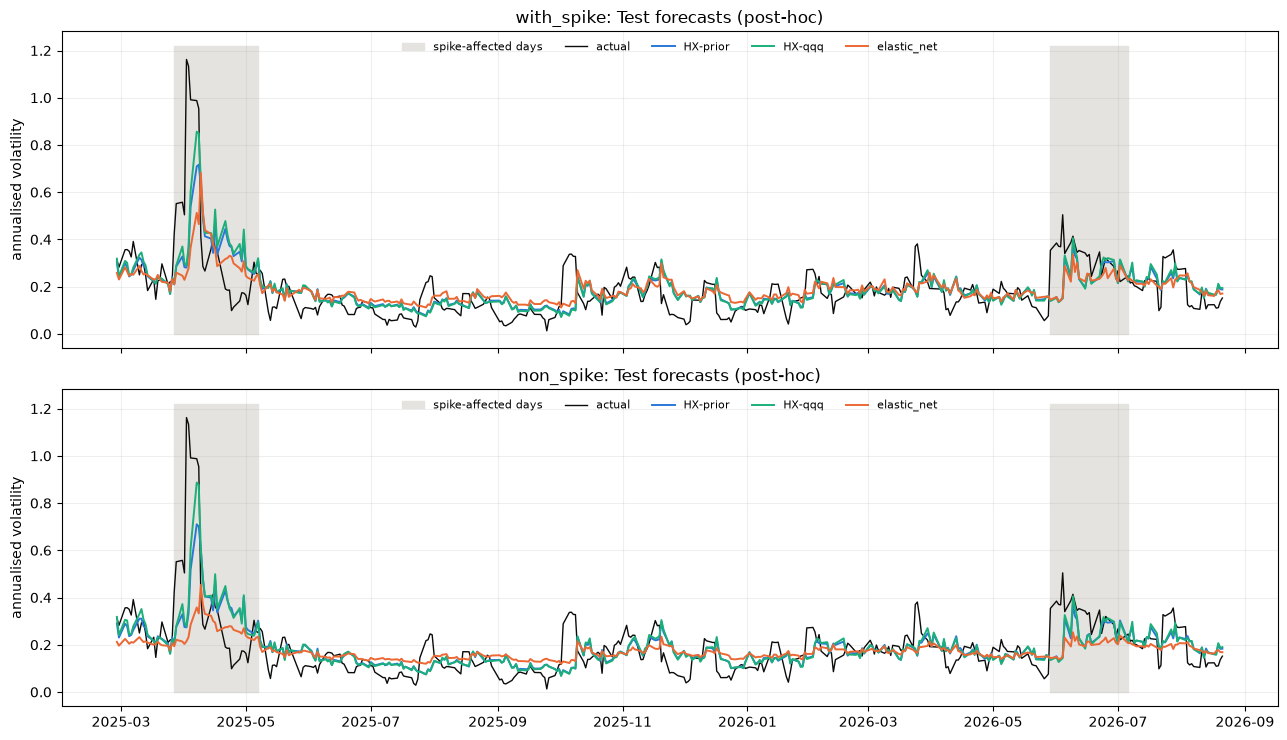

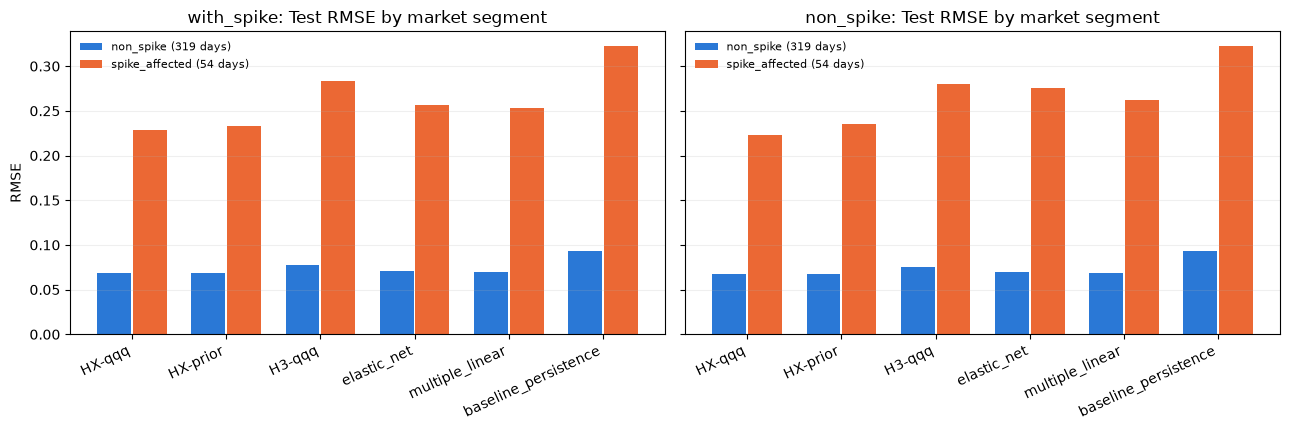

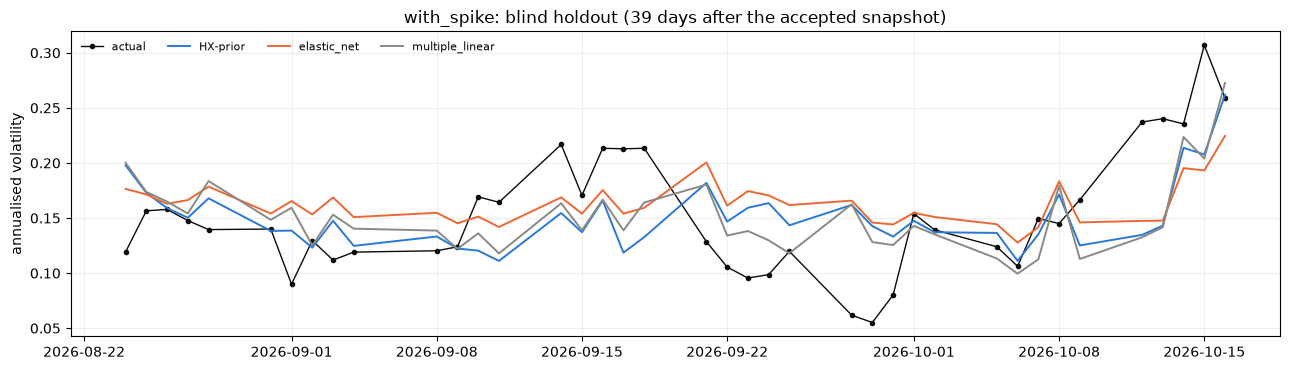

In [25]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
lh = root / "outputs" / "experiments" / "log_har"
ARMS = ["H3-qqq", "HX-qqq", "HX-pool", "HX-prior"]
COLOR = {"HX-prior": "#2a78d6", "HX-qqq": "#1baf7a", "H3-qqq": "#9085e9", "HX-pool": "#2a78d6",
         "elastic_net": "#eb6834", "multiple_linear": "#8a8984", "target": "#0b0b0b"}

show = ["HX-prior", "HX-qqq", "elastic_net"]
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
for ax, variant in zip(axes, ("with_spike", "non_spike")):
    test = pd.read_csv(lh / "test" / variant / "test_predictions.csv", parse_dates=["Date"])
    spike = test["segment"] == "spike_affected"
    ax.fill_between(test["Date"], 0, test["target"].max() * 1.05, where=spike, color="#e4e3df", step="mid",
                    label="spike-affected days")
    ax.plot(test["Date"], test["target"], color="#0b0b0b", linewidth=1, label="actual")
    for name in show:
        ax.plot(test["Date"], test[name], color=COLOR[name], linewidth=1.4, label=name)
    ax.set(title=f"{variant}: Test forecasts (post-hoc)", ylabel="annualised volatility")
    ax.legend(frameon=False, fontsize=8, ncol=5)
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
order = ["HX-qqq", "HX-prior", "H3-qqq", "elastic_net", "multiple_linear", "baseline_persistence"]
for ax, variant in zip(axes, ("with_spike", "non_spike")):
    seg = pd.read_csv(lh / "test" / variant / "segment_metrics.csv")
    x = np.arange(len(order))
    for k, (segment, hue) in enumerate((("non_spike", "#2a78d6"), ("spike_affected", "#eb6834"))):
        part = seg[seg["segment"] == segment].set_index("model").loc[order]
        ax.bar(x + (k - 0.5) * 0.38, part["rmse"], 0.36, color=hue,
               label=f"{segment} ({int(part['rows'].iloc[0])} days)")
    ax.set_xticks(x, order, rotation=25, ha="right")
    ax.set(title=f"{variant}: Test RMSE by market segment")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("RMSE")
fig.tight_layout()
plt.show()

hold = pd.read_csv(lh / "test" / "with_spike" / "holdout_predictions.csv", parse_dates=["Date"])
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(hold["Date"], hold["target"], "o-", color="#0b0b0b", markersize=3, linewidth=1, label="actual")
for name in ("HX-prior", "elastic_net", "multiple_linear"):
    ax.plot(hold["Date"], hold[name], color=COLOR[name], linewidth=1.4, label=name)
ax.set(title="with_spike: blind holdout (39 days after the accepted snapshot)", ylabel="annualised volatility")
ax.legend(frameon=False, fontsize=8, ncol=4)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


**อ่านกราฟ:**

- **ช่วงรอบวัน spike:** ทุกโมเดลทำนายต่ำกว่าจริงมากในวันที่ความผันผวนพุ่ง (ต้นเดือนเมษายน 2025) เพราะฟีเจอร์ทุกตัวมองย้อนหลัง แต่ Log-HAR ขึ้นตามได้เร็วกว่าและสูงกว่า Elastic Net เพราะใช้ช่วงราคาในวัน (`r`) และผลตอบแทนติดลบ (`lev`) ซึ่งตอบสนองทันที
- **RMSE แยกช่วง:** ส่วนต่างระหว่างโมเดลมาจากช่วงรอบวัน spike เป็นหลัก RMSE ของ Log-HAR ในช่วงนั้นราว 0.22 ถึง 0.23 เทียบกับ Elastic Net 0.26 ถึง 0.28 ส่วนในช่วงปกติทุกโมเดลใกล้กันที่ราว 0.07
- **Holdout:** เป็นช่วงสงบคล้าย Validation คำทำนายของทุกโมเดลใกล้กัน multiple_linear ได้ RMSE ต่ำสุด (0.049) Log-HAR อยู่ที่ราว 0.052 จึงสอดคล้องกับผลบน Validation มากกว่า Test

### 13.3 ผลต่างแบบ paired บน Test และผลบน holdout

ผลต่าง RMSE แบบ paired บน Test ด้วย moving-block bootstrap ก้อน 20 วัน 2,000 รอบ (ค่าติดลบแปลว่าตัวแรกดีกว่า) และตาราง metric ของ holdout 39 วัน ซึ่งไม่รายงานช่วงความเชื่อมั่นเพราะสั้นเกินไป

,variant,comparison,difference,95% low,95% high,excludes zero
0,with_spike,HX-prior - elastic_net,-0.00844,-0.01977,0.00399,False
1,with_spike,HX-prior - multiple_linear,-0.00679,-0.01374,-0.00067,True
2,with_spike,HX-prior - HX-qqq,0.00140,-0.00264,0.00510,False
3,with_spike,HX-pool - HX-qqq,0.00140,-0.00264,0.00510,False
4,with_spike,HX-qqq - H3-qqq,-0.02175,-0.03794,-0.00422,True
5,with_spike,HX-prior - baseline_persistence,-0.04125,-0.07032,-0.01718,True
6,non_spike,HX-prior - elastic_net,-0.01390,-0.03039,0.00652,False
7,non_spike,HX-prior - multiple_linear,-0.00896,-0.01718,-0.00092,True
8,non_spike,HX-prior - HX-qqq,0.00357,-0.00043,0.00805,False
9,non_spike,HX-pool - HX-qqq,0.00358,-0.00055,0.00825,False


,variant,model,rows,RMSE,MAE,R2,QLIKE
0,with_spike,HX-prior,39,0.0521,0.0405,0.1150,0.2562
1,with_spike,HX-qqq,39,0.0519,0.0404,0.1223,0.2640
2,with_spike,H3-qqq,39,0.0586,0.0487,-0.1184,0.2847
3,with_spike,elastic_net,39,0.0528,0.0441,0.0906,0.2286
4,with_spike,multiple_linear,39,0.0492,0.0390,0.2098,0.2221
5,with_spike,baseline_persistence,39,0.0690,0.0580,-0.5516,0.5341
6,non_spike,HX-prior,39,0.0522,0.0404,0.1127,0.2702
7,non_spike,HX-qqq,39,0.0514,0.0397,0.1401,0.2676
8,non_spike,H3-qqq,39,0.0580,0.0475,-0.0975,0.2880
9,non_spike,elastic_net,39,0.0525,0.0431,0.1035,0.2310


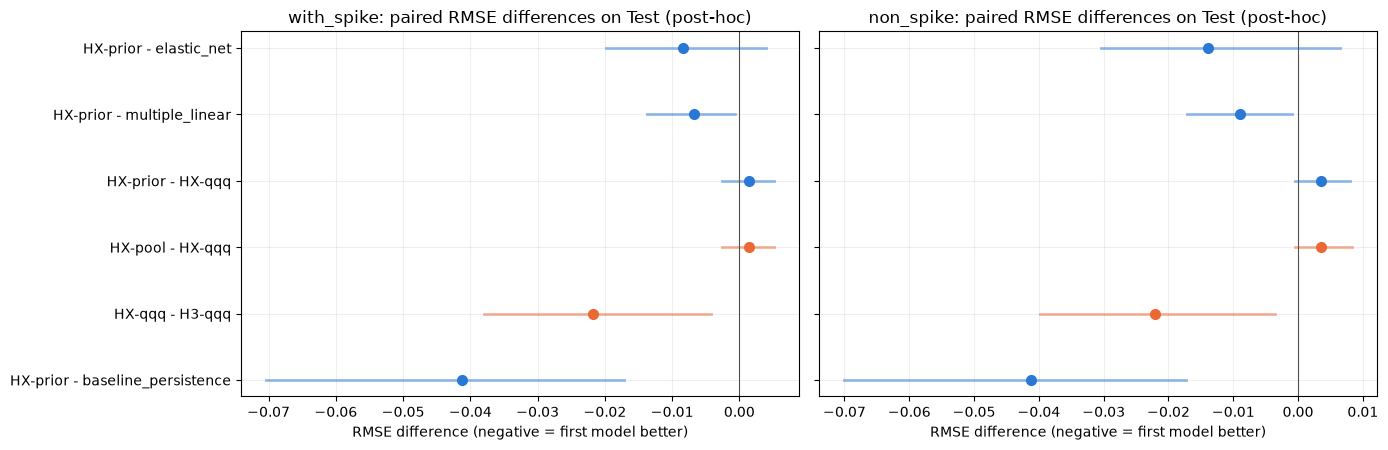

In [26]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
lh = root / "outputs" / "experiments" / "log_har"
ARMS = ["H3-qqq", "HX-qqq", "HX-pool", "HX-prior"]
COLOR = {"HX-prior": "#2a78d6", "HX-qqq": "#1baf7a", "H3-qqq": "#9085e9", "HX-pool": "#2a78d6",
         "elastic_net": "#eb6834", "multiple_linear": "#8a8984", "target": "#0b0b0b"}

def forest(ax, table, title):
    table = table.reset_index(drop=True)
    for i, r in table.iterrows():
        color = "#2a78d6" if r["comparison"].startswith("HX-prior") else "#eb6834"
        ax.plot([r["95% low"], r["95% high"]], [i, i], color=color, linewidth=2, alpha=0.5)
        ax.plot(r["difference"], i, "o", color=color, markersize=7)
    ax.axvline(0, color="#52514e", linewidth=0.8)
    ax.set_yticks(range(len(table)), table["comparison"])
    ax.set(title=title, xlabel="RMSE difference (negative = first model better)")
    ax.grid(alpha=0.2)
PAIRS = ["HX-prior - elastic_net", "HX-prior - multiple_linear", "HX-prior - HX-qqq", "HX-pool - HX-qqq",
         "HX-qqq - H3-qqq", "HX-prior - baseline_persistence"]

rows, holdout = [], []
for variant in ("with_spike", "non_spike"):
    metrics = json.loads((lh / "test" / variant / "test_metrics.json").read_text(encoding="utf-8"))
    for name in PAIRS:
        d = metrics["paired_differences"][name]["rmse"]
        rows.append({"variant": variant, "comparison": name, "difference": d["point"], "95% low": d["low"],
                     "95% high": d["high"], "excludes zero": d["excludes_zero"]})
    hold = json.loads((lh / "test" / variant / "holdout_metrics.json").read_text(encoding="utf-8"))
    for model in ("HX-prior", "HX-qqq", "H3-qqq", "elastic_net", "multiple_linear", "baseline_persistence"):
        m = hold["models"][model]
        holdout.append({"variant": variant, "model": model, "rows": hold["rows"], "RMSE": m["rmse"], "MAE": m["mae"],
                        "R2": m["r2"], "QLIKE": m["qlike"]})
table = pd.DataFrame(rows)
display(table.round(5))
display(pd.DataFrame(holdout).round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, variant in zip(axes, ("with_spike", "non_spike")):
    forest(ax, table[table["variant"] == variant], f"{variant}: paired RMSE differences on Test (post-hoc)")
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()


**ข้อสรุปของการทดลอง Log-HAR:**

1. **ดีกว่า Elastic Net บน Test แต่ยังไม่มีนัย:** RMSE ต่ำกว่า 0.008 และ 0.014 แต่ช่วงคร่อมศูนย์ ส่วนเทียบกับ multiple_linear ดีกว่าอย่างมีนัยทั้งสอง variant
2. **ส่วนที่ช่วยจริงคือฟีเจอร์ ไม่ใช่ transfer:** `HX-qqq − H3-qqq` = −0.022 และช่วงไม่คร่อมศูนย์ทั้งสอง variant ขณะที่ prior จากตลาดอื่นทำให้ RMSE บน Test แย่ลงเล็กน้อย (+0.0014 และ +0.0036) และไม่มีนัย
3. **ทนต่อช่วง spike มากกว่า:** R² ในช่วงรอบวัน spike ของ Log-HAR เป็นบวก ขณะที่ Elastic Net และ multiple_linear ติดลบ
4. **ข้อจำกัด:** ผล Test เป็น post-hoc และกลับทิศกับ Validation ที่สงบ จึงยังอ้างไม่ได้ว่า Log-HAR ดีกว่า Elastic Net ข้อมูลอนาคตที่มีช่วงผันผวนจะเป็นหลักฐานที่ดีกว่า